In [1]:
path = "/kaggle/input/mertosu/processed-metadata/processed-metadata.csv"

In [2]:
import pandas as pd
from pathlib import Path

df = pd.read_csv(path)

base_map = Path("/kaggle/input/mertosu/processed-beatmaps-unparseForm")
base_audio = Path("/kaggle/input/mertosu/mert-preprocessed")
base_hyper = Path("/kaggle/input/mertosu/processed-hyperparam")

df["beatmap_path"] = df["file_md5"].apply(lambda x: base_map / f"{x}-d.npy")
df["audio_feature_path"] = df["file_md5"].apply(lambda x: base_audio / f"{x}.npy")
df["hyper_path"] = df["file_md5"].apply(lambda x: base_hyper / f"{x}-b.json")


In [3]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import json


# -------------------------------------------------
# JSON hyperparam loader
# -------------------------------------------------
def load_hyper_json(path):
    with open(path, "r") as f:
        data = json.load(f)

    if isinstance(data, dict):
        # deterministic key order → consistent feature vector
        data = [data[k] for k in sorted(data.keys())]

    return np.asarray(data, dtype=np.float32)


# -------------------------------------------------
# Extract features from weird audio format:
# each row = [timestamp, feature_vector]
# -------------------------------------------------
def extract_audio_features(obj_arr):
    """Drop timestamps and keep only feature vectors"""
    features = [row[1] for row in obj_arr]
    return np.vstack(features).astype(np.float32)


class OsuDataset(Dataset):
    def __init__(self, df):
        self.df = df

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # -------------------------------------------------
        # AUDIO: drop timestamp, keep only feature vectors
        # -------------------------------------------------
        audio = np.load(row["audio_feature_path"], allow_pickle=True)
        if audio.dtype == object:
            audio = extract_audio_features(audio)
        else:
            audio = np.asarray(audio, dtype=np.float32)
        
        # CRITICAL FIX: Replace NaN/Inf in audio with zeros
        audio = np.nan_to_num(audio, nan=0.0, posinf=0.0, neginf=0.0)

        # -------------------------------------------------
        # BEATMAP: drop timestamp + normalize x,y to [-1,1]
        # Original beatmap = [x, y, timestamp, hittype]
        # -------------------------------------------------
        beatmap = np.load(row["beatmap_path"], allow_pickle=True)
        beatmap = np.asarray(beatmap, dtype=np.float32)

        # drop timestamp → keep x, y, hittype
        beatmap = beatmap[:, [0, 1, 3]]

        # normalize x,y to [-1, 1] (x_max=512, y_max=384)
        beatmap[:, 0] = (beatmap[:, 0] / 512.0) * 2.0 - 1.0  # x
        beatmap[:, 1] = (beatmap[:, 1] / 384.0) * 2.0 - 1.0  # y
        
        # Clean beatmap data
        beatmap = np.nan_to_num(beatmap, nan=0.0, posinf=0.0, neginf=0.0)
        
        # hittype: convert to long for CrossEntropyLoss (keep as class indices 0-5)
        # NOTE: hittype stays as integer class labels, NOT normalized

        # -------------------------------------------------
        # HYPER: metadata (no normalization needed)
        # -------------------------------------------------
        hyper = load_hyper_json(row["hyper_path"])
        hyper = np.nan_to_num(hyper, nan=0.0, posinf=0.0, neginf=0.0)

        return {
            "audio": torch.tensor(audio, dtype=torch.float32),
            "beatmap": torch.tensor(beatmap, dtype=torch.float32),
            "hyper": torch.tensor(hyper, dtype=torch.float32)
        }


# -------------------------------------------------
# Collate function: pads sequences to batch max length
# IMPORTANT: Ensures audio and beatmap have same sequence length
# -------------------------------------------------
def collate_fn(batch):
    audios = [item["audio"] for item in batch]
    beatmaps = [item["beatmap"] for item in batch]
    hypers = [item["hyper"] for item in batch]

    # Get max length across BOTH audio and beatmap
    audio_lens = [a.shape[0] for a in audios]
    bm_lens = [b.shape[0] for b in beatmaps]
    max_len = max(max(audio_lens), max(bm_lens))  # Use same max for both
    
    audio_dim = audios[0].shape[1]
    bm_dim = beatmaps[0].shape[1]

    # Pad both to same max length
    padded_audio = torch.zeros(len(batch), max_len, audio_dim)
    for i, a in enumerate(audios):
        padded_audio[i, :a.shape[0]] = a

    padded_bm = torch.zeros(len(batch), max_len, bm_dim)
    for i, b in enumerate(beatmaps):
        padded_bm[i, :b.shape[0]] = b

    hyper_tensor = torch.stack(hypers)

    return {
        "audio": padded_audio,
        "audio_lengths": torch.tensor(audio_lens),
        "beatmap": padded_bm,
        "beatmap_lengths": torch.tensor(bm_lens),
        "hyper": hyper_tensor,
    }


# -------------------------------------------------
# Dataloader factory
# -------------------------------------------------
def make_dataloader(df, batch_size=8, shuffle=True):
    dataset = OsuDataset(df)
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        collate_fn=collate_fn,
        num_workers=2,
        pin_memory=True
    )
    return dataset, loader

print("✓ Dataset updated for multi-class hittype (6 classes: 0-5)")
print("✓ NaN/Inf cleaning applied to audio, beatmap, and hyper features")


✓ Dataset updated for multi-class hittype (6 classes: 0-5)
✓ NaN/Inf cleaning applied to audio, beatmap, and hyper features


In [4]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import json
from scipy.interpolate import interp1d


# -------------------------------------------------
# JSON hyperparam loader
# -------------------------------------------------
def load_hyper_json(path):
    with open(path, "r") as f:
        data = json.load(f)

    if isinstance(data, dict):
        # deterministic key order → consistent feature vector
        data = [data[k] for k in sorted(data.keys())]

    return np.asarray(data, dtype=np.float32)


# -------------------------------------------------
# Extract features from weird audio format:
# each row = [timestamp, feature_vector]
# NOW KEEPS TIMESTAMPS!
# -------------------------------------------------
def extract_audio_features(obj_arr):
    """Keep timestamps AND feature vectors"""
    # Each row is [timestamp, feature_vector]
    # We'll return [timestamp, ...features]
    result = []
    for row in obj_arr:
        timestamp = row[0]
        features = row[1]
        # Concatenate timestamp with features
        combined = np.concatenate([[timestamp], features])
        result.append(combined)
    return np.vstack(result).astype(np.float32)


# -------------------------------------------------
# Align audio to beatmap timestamps via interpolation
# -------------------------------------------------
def align_audio_to_beatmap(audio, beatmap):
    """
    Interpolate audio features to match beatmap timestamps exactly.
    
    audio: shape (N_audio, D_audio) where first column is timestamp
    beatmap: shape (N_beatmap, 4) where column 2 is timestamp
    
    Returns: aligned_audio with shape (N_beatmap, D_audio)
    """
    # Extract timestamps
    audio_times = audio[:, 0]
    beatmap_times = beatmap[:, 2]
    
    # Extract features (excluding timestamp column)
    audio_features = audio[:, 1:]
    
    # Interpolate each audio feature dimension to beatmap timestamps
    aligned_features = np.zeros((len(beatmap_times), audio_features.shape[1]), dtype=np.float32)
    
    for feat_idx in range(audio_features.shape[1]):
        # Create interpolator for this feature
        interpolator = interp1d(
            audio_times, 
            audio_features[:, feat_idx],
            kind='linear',
            bounds_error=False,
            fill_value='extrapolate'
        )
        # Interpolate to beatmap timestamps
        aligned_features[:, feat_idx] = interpolator(beatmap_times)
    
    # Combine beatmap timestamps with interpolated features
    aligned_audio = np.concatenate([
        beatmap_times[:, np.newaxis],  # Use beatmap timestamps
        aligned_features
    ], axis=1).astype(np.float32)
    
    return aligned_audio


class OsuDataset(Dataset):
    def __init__(self, df):
        self.df = df

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # -------------------------------------------------
        # AUDIO: KEEP timestamp with feature vectors
        # -------------------------------------------------
        audio = np.load(row["audio_feature_path"], allow_pickle=True)
        if audio.dtype == object:
            audio = extract_audio_features(audio)
        else:
            audio = np.asarray(audio, dtype=np.float32)
        
        # CRITICAL FIX: Replace NaN/Inf in audio with zeros
        audio = np.nan_to_num(audio, nan=0.0, posinf=0.0, neginf=0.0)

        # -------------------------------------------------
        # BEATMAP: KEEP ALL COLUMNS [x, y, timestamp, hittype]
        # -------------------------------------------------
        beatmap = np.load(row["beatmap_path"], allow_pickle=True)
        beatmap = np.asarray(beatmap, dtype=np.float32)

        # Keep all columns: x, y, timestamp, hittype
        # beatmap shape: (seq_len, 4)

        # normalize x,y to [-1, 1] (x_max=512, y_max=384)
        beatmap[:, 0] = (beatmap[:, 0] / 512.0) * 2.0 - 1.0  # x
        beatmap[:, 1] = (beatmap[:, 1] / 384.0) * 2.0 - 1.0  # y
        # timestamp (column 2) stays as-is
        # hittype (column 3) stays as-is (integer class labels 0-5)
        
        # Clean beatmap data
        beatmap = np.nan_to_num(beatmap, nan=0.0, posinf=0.0, neginf=0.0)

        # -------------------------------------------------
        # ALIGN AUDIO TO BEATMAP TIMESTAMPS
        # -------------------------------------------------
        audio = align_audio_to_beatmap(audio, beatmap)

        # -------------------------------------------------
        # HYPER: metadata (no normalization needed)
        # -------------------------------------------------
        hyper = load_hyper_json(row["hyper_path"])
        hyper = np.nan_to_num(hyper, nan=0.0, posinf=0.0, neginf=0.0)

        return {
            "audio": torch.tensor(audio, dtype=torch.float32),
            "beatmap": torch.tensor(beatmap, dtype=torch.float32),
            "hyper": torch.tensor(hyper, dtype=torch.float32)
        }


# -------------------------------------------------
# Collate function: pads sequences to batch max length
# IMPORTANT: Ensures audio and beatmap have same sequence length
# -------------------------------------------------
def collate_fn(batch):
    audios = [item["audio"] for item in batch]
    beatmaps = [item["beatmap"] for item in batch]
    hypers = [item["hyper"] for item in batch]

    # Get max length across BOTH audio and beatmap
    audio_lens = [a.shape[0] for a in audios]
    bm_lens = [b.shape[0] for b in beatmaps]
    max_len = max(max(audio_lens), max(bm_lens))  # Use same max for both
    
    audio_dim = audios[0].shape[1]
    bm_dim = beatmaps[0].shape[1]

    # Pad both to same max length
    padded_audio = torch.zeros(len(batch), max_len, audio_dim)
    for i, a in enumerate(audios):
        padded_audio[i, :a.shape[0]] = a

    padded_bm = torch.zeros(len(batch), max_len, bm_dim)
    for i, b in enumerate(beatmaps):
        padded_bm[i, :b.shape[0]] = b

    hyper_tensor = torch.stack(hypers)

    return {
        "audio": padded_audio,
        "audio_lengths": torch.tensor(audio_lens),
        "beatmap": padded_bm,
        "beatmap_lengths": torch.tensor(bm_lens),
        "hyper": hyper_tensor,
    }


# -------------------------------------------------
# Dataloader factory
# -------------------------------------------------
def make_dataloader(df, batch_size=8, shuffle=True):
    dataset = OsuDataset(df)
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        collate_fn=collate_fn,
        num_workers=2,
        pin_memory=True
    )
    return dataset, loader

print("✓ Dataset updated - TIMESTAMPS NOW ALIGNED")
print("✓ Audio features interpolated to match beatmap timestamps EXACTLY")
print("✓ Audio: [timestamp, ...features] - timestamps match beatmap")
print("✓ Beatmap: [x, y, timestamp, hittype]")
print("✓ NaN/Inf cleaning applied to audio, beatmap, and hyper features")


✓ Dataset updated - TIMESTAMPS NOW ALIGNED
✓ Audio features interpolated to match beatmap timestamps EXACTLY
✓ Audio: [timestamp, ...features] - timestamps match beatmap
✓ Beatmap: [x, y, timestamp, hittype]
✓ NaN/Inf cleaning applied to audio, beatmap, and hyper features


In [9]:
# Extract and display ONLY timestamps
print("=" * 60)
print("TIMESTAMPS ONLY")
print("=" * 60)

# Audio timestamps (first column, index 0)
audio_timestamps = batch['audio'][0, :, 0]
print(f"\nAudio timestamps (first item in batch):")
print(f"Shape: {audio_timestamps.shape}")
print(f"First 10 timesteps: {audio_timestamps[:10].tolist()}")
print(f"Last 10 timesteps: {audio_timestamps[-10:].tolist()}")

# Beatmap timestamps (third column, index 2)
beatmap_timestamps = batch['beatmap'][0, :, 2]
print(f"\n\nBeatmap timestamps (first item in batch):")
print(f"Shape: {beatmap_timestamps.shape}")
print(f"First 10 timesteps: {beatmap_timestamps[:10].tolist()}")
print(f"Last 10 timesteps: {beatmap_timestamps[-10:].tolist()}")

# Show actual sequence length (non-padded)
actual_audio_len = batch['audio_lengths'][0].item()
actual_beatmap_len = batch['beatmap_lengths'][0].item()

print(f"\n\nActual sequence lengths (before padding):")
print(f"  Audio: {actual_audio_len} timesteps")
print(f"  Beatmap: {actual_beatmap_len} timesteps")

print(f"\n\nAudio timestamps (non-padded):")
print(audio_timestamps[:actual_audio_len].tolist())

print(f"\n\nBeatmap timestamps (non-padded):")
print(beatmap_timestamps[:actual_beatmap_len].tolist())

TIMESTAMPS ONLY

Audio timestamps (first item in batch):
Shape: torch.Size([1207])
First 10 timesteps: [455.0, 537.0, 620.0, 703.0, 786.0, 869.0, 952.0, 1035.0, 1117.0, 1200.0]
Last 10 timesteps: [99653.0, 99736.0, 99819.0, 99902.0, 99985.0, 100068.0, 100151.0, 100234.0, 100316.0, 100399.0]


Beatmap timestamps (first item in batch):
Shape: torch.Size([1207])
First 10 timesteps: [455.0, 537.0, 620.0, 703.0, 786.0, 869.0, 952.0, 1035.0, 1117.0, 1200.0]
Last 10 timesteps: [99653.0, 99736.0, 99819.0, 99902.0, 99985.0, 100068.0, 100151.0, 100234.0, 100316.0, 100399.0]


Actual sequence lengths (before padding):
  Audio: 1207 timesteps
  Beatmap: 1207 timesteps


Audio timestamps (non-padded):
[455.0, 537.0, 620.0, 703.0, 786.0, 869.0, 952.0, 1035.0, 1117.0, 1200.0, 1283.0, 1366.0, 1449.0, 1532.0, 1615.0, 1698.0, 1780.0, 1863.0, 1946.0, 2029.0, 2112.0, 2195.0, 2278.0, 2361.0, 2443.0, 2526.0, 2609.0, 2692.0, 2775.0, 2858.0, 2941.0, 3024.0, 3106.0, 3189.0, 3272.0, 3355.0, 3438.0, 3521.0, 3604

In [11]:
# Create DataLoader - ready for GAN, LSTM, or any PyTorch model
dataset, loader = make_dataloader(df, batch_size=8, shuffle=True)

print(f"Dataset size: {len(dataset)}")
print(f"\nLoading first batch...")

# Get one batch to verify shapes
batch = next(iter(loader))

print(f"\nBatch structure:")
print(f"  Audio shape: {batch['audio'].shape}")  # (batch, seq_len, 1+audio_features) → [timestamp, ...features]
print(f"  Audio lengths: {batch['audio_lengths']}")
print(f"  Beatmap shape: {batch['beatmap'].shape}")  # (batch, seq_len, 4) → [x, y, timestamp, hittype]
print(f"  Beatmap lengths: {batch['beatmap_lengths']}")
print(f"  Hyper shape: {batch['hyper'].shape}")  # (batch, n_hyperparams)

print(f"\n✓ X,Y normalized to [-1, 1] (x_max=512, y_max=384)")
print(f"✓ TIMESTAMPS INCLUDED and ALIGNED in both audio and beatmap")
print(f"✓ Audio: [timestamp, ...features] - timestamps match beatmap exactly")
print(f"✓ Beatmap: [x_norm, y_norm, timestamp, hittype]")
print(f"✓ Ready for GAN/LSTM/Transformer models!")

# Show sample data from first item in batch
print(f"\n--- Sample data from first item ---")
print(f"First 3 audio rows:\n{batch['audio'][0, :3]}")
print(f"\nFirst 3 beatmap rows:\n{batch['beatmap'][0, :3]}")

# Verify timestamp alignment
print(f"\n--- Timestamp Alignment Check ---")
audio_ts = batch['audio'][0, :10, 0]
beatmap_ts = batch['beatmap'][0, :10, 2]
print(f"Audio timestamps (first 10):    {audio_ts.tolist()}")
print(f"Beatmap timestamps (first 10):  {beatmap_ts.tolist()}")
print(f"Timestamps match: {torch.allclose(audio_ts, beatmap_ts)}")


Dataset size: 6008

Loading first batch...

Batch structure:
  Audio shape: torch.Size([8, 1140, 769])
  Audio lengths: tensor([1140,  932, 1091, 1118,  808, 1089,  804, 1040])
  Beatmap shape: torch.Size([8, 1140, 4])
  Beatmap lengths: tensor([1140,  932, 1091, 1118,  808, 1089,  804, 1040])
  Hyper shape: torch.Size([8, 7])

✓ X,Y normalized to [-1, 1] (x_max=512, y_max=384)
✓ TIMESTAMPS INCLUDED and ALIGNED in both audio and beatmap
✓ Audio: [timestamp, ...features] - timestamps match beatmap exactly
✓ Beatmap: [x_norm, y_norm, timestamp, hittype]
✓ Ready for GAN/LSTM/Transformer models!

--- Sample data from first item ---
First 3 audio rows:
tensor([[ 5.3700e+02, -5.3940e-02,  2.5231e-01,  ...,  1.6698e-02,
         -2.2969e-02, -6.9375e-02],
        [ 6.1500e+02, -2.1440e-01, -6.4368e-02,  ..., -3.7918e-02,
          6.9868e-02, -2.8886e-01],
        [ 6.9400e+02,  1.2874e-02,  3.2664e-02,  ...,  1.8429e-01,
         -2.2052e-01,  1.4562e-02]])

First 3 beatmap rows:
tensor([[-6

In [10]:
# Create DataLoader - ready for GAN, LSTM, or any PyTorch model
dataset, loader = make_dataloader(df, batch_size=8, shuffle=True)

print(f"Dataset size: {len(dataset)}")
print(f"\nLoading first batch...")

# Get one batch to verify shapes
batch = next(iter(loader))

print(f"\nBatch structure:")
print(f"  Audio shape: {batch['audio'].shape}")  # (batch, seq_len, audio_features)
print(f"  Audio lengths: {batch['audio_lengths']}")
print(f"  Beatmap shape: {batch['beatmap'].shape}")  # (batch, seq_len, 3) → [x, y, hittype]
print(f"  Beatmap lengths: {batch['beatmap_lengths']}")
print(f"  Hyper shape: {batch['hyper'].shape}")  # (batch, n_hyperparams)

print(f"\n✓ X,Y normalized to [-1, 1] (x_max=512, y_max=384)")
print(f"✓ Timestamps dropped from audio and beatmap")
print(f"✓ Ready for GAN/LSTM/Transformer models!")


Dataset size: 6008

Loading first batch...

Batch structure:
  Audio shape: torch.Size([8, 1220, 769])
  Audio lengths: tensor([1070, 1143, 1014,  828,  811, 1220, 1112,  954])
  Beatmap shape: torch.Size([8, 1220, 4])
  Beatmap lengths: tensor([1070, 1143, 1014,  828,  811, 1220, 1112,  954])
  Hyper shape: torch.Size([8, 7])

✓ X,Y normalized to [-1, 1] (x_max=512, y_max=384)
✓ Timestamps dropped from audio and beatmap
✓ Ready for GAN/LSTM/Transformer models!


In [5]:
# -------------------------------------------------
# Train/Validation Split
# -------------------------------------------------
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(df, test_size=0.1, random_state=42)

train_dataset, train_loader = make_dataloader(train_df, batch_size=8, shuffle=True)
val_dataset, val_loader = make_dataloader(val_df, batch_size=8, shuffle=False)

print(f"✓ Train samples: {len(train_dataset)}")
print(f"✓ Validation samples: {len(val_dataset)}")
print(f"✓ Ready to train!")



✓ Train samples: 5407
✓ Validation samples: 601
✓ Ready to train!


In [12]:
# -------------------------------------------------
# Train/Validation/Test Split
# -------------------------------------------------
from sklearn.model_selection import train_test_split

# First split: train vs temp (val+test)
train_df, temp_df = train_test_split(
    df, test_size=0.2, random_state=42
)

# Second split: val vs test (each 10% of original)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42
)

train_dataset, train_loader = make_dataloader(train_df, batch_size=8, shuffle=True)
val_dataset, val_loader = make_dataloader(val_df, batch_size=8, shuffle=False)
test_dataset, test_loader = make_dataloader(test_df, batch_size=8, shuffle=False)

print(f"✓ Train samples: {len(train_dataset)}")
print(f"✓ Validation samples: {len(val_dataset)}")
print(f"✓ Test samples: {len(test_dataset)}")
print("✓ Ready to train!")


✓ Train samples: 4806
✓ Validation samples: 601
✓ Test samples: 601
✓ Ready to train!


In [13]:
# -------------------------------------------------
# Clear CUDA cache and reset (run if you get CUDA errors)
# -------------------------------------------------
import gc
import torch

# Clear Python garbage
gc.collect()

# Clear CUDA cache
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.synchronize()
    print("✓ CUDA cache cleared")
else:
    print("✓ CPU mode - no cache to clear")

print("\n⚠️ If you still get CUDA errors:")
print("   1. Restart the kernel (Kernel → Restart)")
print("   2. Re-run all cells from the beginning")


✓ CUDA cache cleared

⚠️ If you still get CUDA errors:
   1. Restart the kernel (Kernel → Restart)
   2. Re-run all cells from the beginning


Visualizing objects 51 to 70 (Total available: 1054)


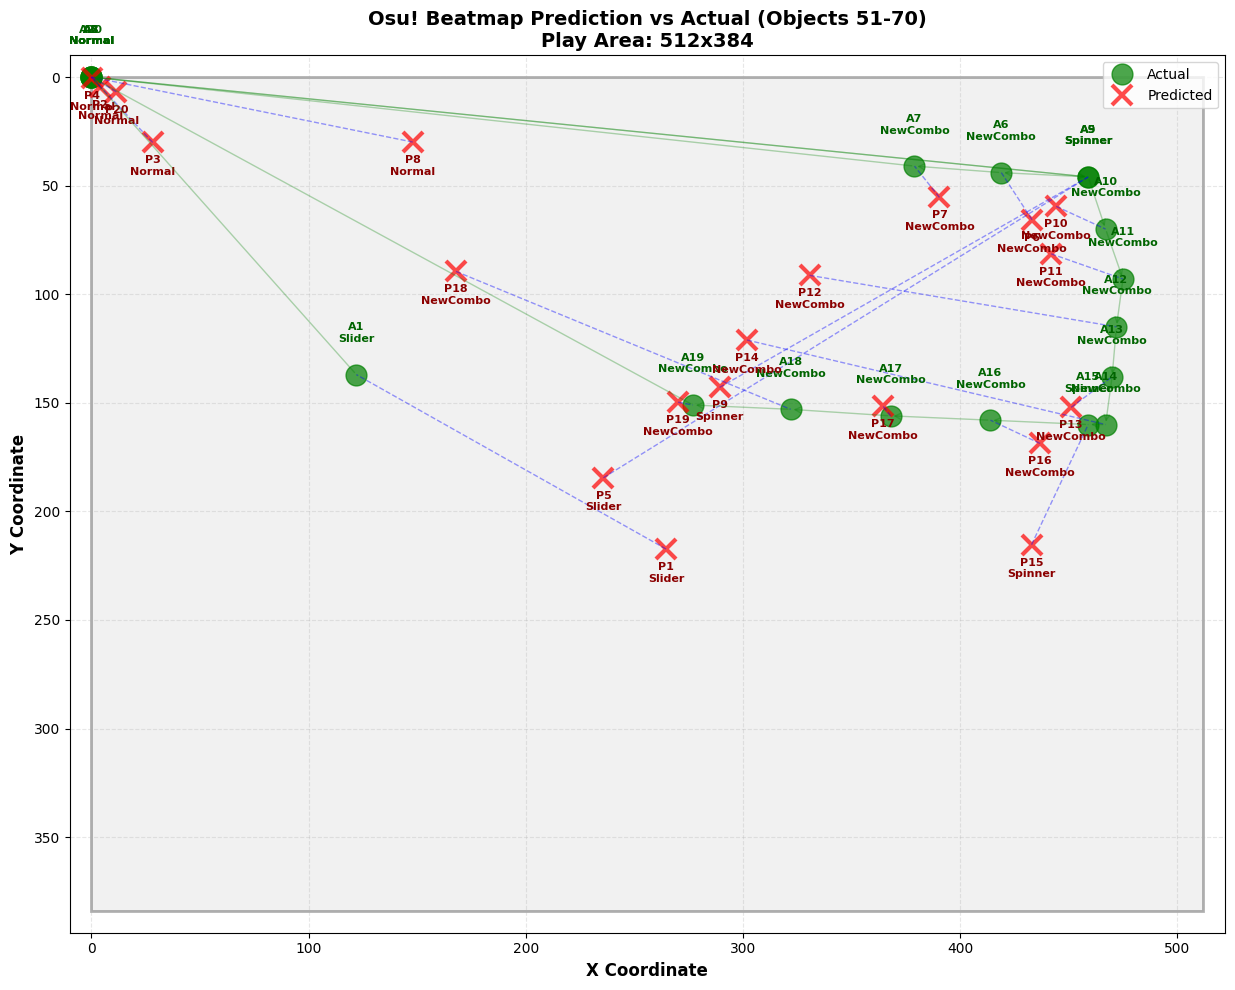


Detailed Comparison for Objects 51-70

Object 1:
  Predicted: ( 264.6,  217.3) - Slider
  Actual:    ( 122.0,  137.0) - Slider
  Error:     X= 142.6px, Y=  80.3px, Distance= 163.7px ✓

Object 2:
  Predicted: (   4.1,    4.4) - Normal
  Actual:    (   0.0,    0.0) - Normal
  Error:     X=   4.1px, Y=   4.4px, Distance=   6.0px ✓

Object 3:
  Predicted: (  28.2,   30.1) - Normal
  Actual:    (   0.0,    0.0) - Normal
  Error:     X=  28.2px, Y=  30.1px, Distance=  41.3px ✓

Object 4:
  Predicted: (   0.4,    0.3) - Normal
  Actual:    (   0.0,    0.0) - Normal
  Error:     X=   0.4px, Y=   0.3px, Distance=   0.5px ✓

Object 5:
  Predicted: ( 235.8,  184.5) - Slider
  Actual:    ( 459.0,   46.0) - Spinner
  Error:     X= 223.2px, Y= 138.5px, Distance= 262.7px ✗

Object 6:
  Predicted: ( 433.1,   65.7) - NewCombo
  Actual:    ( 419.0,   44.0) - NewCombo
  Error:     X=  14.1px, Y=  21.7px, Distance=  25.9px ✓

Object 7:
  Predicted: ( 390.5,   55.4) - NewCombo
  Actual:    ( 379.0,   41.0

In [17]:
# -------------------------------------------------
# Visualize Predicted vs Actual on 512x384 Play Area
# -------------------------------------------------

import matplotlib.pyplot as plt
import matplotlib.patches as patches

# ===== MODIFY THESE PARAMETERS =====
chunk_start = 50   # Starting index (0 for first object, 20 for second chunk, etc.)
chunk_size = 20      # Number of hit objects to visualize
# ====================================

chunk_end = min(chunk_start + chunk_size, length[0])
print(f"Visualizing objects {chunk_start+1} to {chunk_end} (Total available: {length[0]})")

# Extract the chunk
pred_x_chunk = pred_x[chunk_start:chunk_end]
pred_y_chunk = pred_y[chunk_start:chunk_end]
actual_x_chunk = actual_x[chunk_start:chunk_end]
actual_y_chunk = actual_y[chunk_start:chunk_end]
pred_hit_chunk = pred_hittype_np[chunk_start:chunk_end]
actual_hit_chunk = actual_hittype_np[chunk_start:chunk_end]

# Create figure with play area
fig, ax = plt.subplots(figsize=(14, 10))

# Draw the play area (512x384)
rect = patches.Rectangle((0, 0), 512, 384, linewidth=2, edgecolor='black', facecolor='lightgray', alpha=0.3)
ax.add_patch(rect)

# Hit type names for legend
hit_types = {0: 'Normal', 1: 'Slider', 2: 'Spinner', 3: 'NewCombo', 4: 'SliderCombo', 5: 'SpinnerCombo'}

# Plot actual positions (green circles)
for i in range(len(actual_x_chunk)):
    ax.plot(actual_x_chunk[i], actual_y_chunk[i], 'go', markersize=15, alpha=0.7, label='Actual' if i == 0 else '')
    ax.text(actual_x_chunk[i], actual_y_chunk[i] - 15, f'A{i+1}\n{hit_types[actual_hit_chunk[i]]}', 
            ha='center', fontsize=8, color='darkgreen', fontweight='bold')

# Plot predicted positions (red crosses)
for i in range(len(pred_x_chunk)):
    ax.plot(pred_x_chunk[i], pred_y_chunk[i], 'rx', markersize=15, markeredgewidth=3, alpha=0.7, label='Predicted' if i == 0 else '')
    ax.text(pred_x_chunk[i], pred_y_chunk[i] + 15, f'P{i+1}\n{hit_types[pred_hit_chunk[i]]}', 
            ha='center', fontsize=8, color='darkred', fontweight='bold')

# Draw lines connecting predicted to actual (error visualization)
for i in range(len(pred_x_chunk)):
    ax.plot([pred_x_chunk[i], actual_x_chunk[i]], [pred_y_chunk[i], actual_y_chunk[i]], 
            'b--', alpha=0.4, linewidth=1)

# Draw sequence order (connecting actual positions)
for i in range(len(actual_x_chunk) - 1):
    ax.annotate('', xy=(actual_x_chunk[i+1], actual_y_chunk[i+1]), 
                xytext=(actual_x_chunk[i], actual_y_chunk[i]),
                arrowprops=dict(arrowstyle='->', color='green', alpha=0.3, lw=1))

# Set plot properties
ax.set_xlim(-10, 522)
ax.set_ylim(-10, 394)
ax.set_xlabel('X Coordinate', fontsize=12, fontweight='bold')
ax.set_ylabel('Y Coordinate', fontsize=12, fontweight='bold')
ax.set_title(f'Osu! Beatmap Prediction vs Actual (Objects {chunk_start+1}-{chunk_end})\nPlay Area: 512x384', 
             fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, linestyle='--')
ax.legend(loc='upper right', fontsize=10)
ax.set_aspect('equal')

# Invert y-axis to match osu! coordinate system (0,0 at top-left)
ax.invert_yaxis()

plt.tight_layout()
plt.show()

# Print detailed comparison for the chunk
print("\n" + "=" * 80)
print(f"Detailed Comparison for Objects {chunk_start+1}-{chunk_end}")
print("=" * 80)
for i in range(len(pred_x_chunk)):
    error_x = abs(pred_x_chunk[i] - actual_x_chunk[i])
    error_y = abs(pred_y_chunk[i] - actual_y_chunk[i])
    error_dist = np.sqrt(error_x**2 + error_y**2)
    hit_match = "✓" if pred_hit_chunk[i] == actual_hit_chunk[i] else "✗"
    
    print(f"\nObject {i+1}:")
    print(f"  Predicted: ({pred_x_chunk[i]:6.1f}, {pred_y_chunk[i]:6.1f}) - {hit_types[pred_hit_chunk[i]]}")
    print(f"  Actual:    ({actual_x_chunk[i]:6.1f}, {actual_y_chunk[i]:6.1f}) - {hit_types[actual_hit_chunk[i]]}")
    print(f"  Error:     X={error_x:6.1f}px, Y={error_y:6.1f}px, Distance={error_dist:6.1f}px {hit_match}")

print("=" * 80)

In [33]:
# ===== MODIFY THESE FILE PATHS =====
audio_file = "/kaggle/input/mertosu/mert-preprocessed/001062647ac2189767df427cf66882c1.npy"        # Audio embeddings file
hyperparam_file = "/kaggle/input/mertosu/processed-hyperparam/001062647ac2189767df427cf66882c1-b.json"    # Hyperparameters file
actual_output_file = "/kaggle/input/mertosu/processed-beatmaps/001062647ac2189767df427cf66882c1-b.npy"  # Actual beatmap file
# ====================================

# **Adv**

In [12]:
# -------------------------------------------------
# Diffusion Model for Beatmap Generation (FIXED - No Future Leakage)
# -------------------------------------------------
import torch
import torch.nn as nn
import numpy as np

class SinusoidalTimeEmbedding(nn.Module):
    """Embed diffusion timestep (which denoising step we're at)"""
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    
    def forward(self, t):
        device = t.device
        half_dim = self.dim // 2
        embeddings = np.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = t[:, None] * embeddings[None, :]
        embeddings = torch.cat([torch.sin(embeddings), torch.cos(embeddings)], dim=-1)
        return embeddings


class DiffusionBeatmapModel(nn.Module):
    """
    Diffusion Model: Predicts noise to remove at each denoising step
    
    ✅ FIXED: No future leakage - uses causal masking
    ✅ FIXED: Conditions on previous outputs (x, y, hittype)
    ✅ FIXED: Conditions on current hittype
    
    Inputs:
        - noisy_beatmap: (batch, seq_len, 2) - current noisy x, y
        - timestep: (batch,) - diffusion timestep
        - audio: (batch, seq_len, 768) - audio features (can see all, it's the condition)
        - hyper: (batch, 7) - hyperparameters
        - prev_beatmap: (batch, seq_len, 3) - SHIFTED previous outputs [x, y, hittype]
        - current_hittype: (batch, seq_len) - current hittype (given, not predicted)
    
    Output:
        - predicted_noise: (batch, seq_len, 2) - noise to subtract from x, y
    """
    def __init__(
        self,
        audio_dim=768,
        hyper_dim=7,
        beatmap_dim=2,  # x, y coordinates (output)
        prev_beatmap_dim=3,  # previous x, y, hittype
        hittype_embed_dim=32,
        time_embed_dim=64,
        d_model=256,
        nhead=8,
        num_layers=8,
        dropout=0.1,
        num_hittype_classes=6
    ):
        super().__init__()
        
        self.d_model = d_model
        
        # Time embedding (which denoising step)
        self.time_embed = nn.Sequential(
            SinusoidalTimeEmbedding(time_embed_dim),
            nn.Linear(time_embed_dim, time_embed_dim * 2),
            nn.SiLU(),
            nn.Linear(time_embed_dim * 2, time_embed_dim)
        )
        
        # Project noisy beatmap (current x, y being denoised)
        self.beatmap_proj = nn.Linear(beatmap_dim, d_model)
        
        # Project audio condition
        self.audio_proj = nn.Linear(audio_dim, d_model)
        
        # Project hyper condition
        self.hyper_proj = nn.Linear(hyper_dim, 64)
        
        # Project PREVIOUS outputs (shifted - so position i sees outputs 0..i-1)
        self.prev_beatmap_proj = nn.Sequential(
            nn.Linear(prev_beatmap_dim, d_model),
            nn.LayerNorm(d_model),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        
        # Embed CURRENT hittype (given as input, not predicted)
        self.hittype_embedding = nn.Embedding(num_hittype_classes, hittype_embed_dim)
        
        # Combine all inputs:
        # noisy_beatmap + audio + hyper + prev_beatmap + current_hittype + timestep
        combined_dim = d_model + d_model + 64 + d_model + hittype_embed_dim + time_embed_dim
        self.input_combine = nn.Linear(combined_dim, d_model)
        
        # Positional encoding
        self.pos_encoder = PositionalEncoding(d_model, max_len=5000)
        
        # Transformer with CAUSAL MASKING (no future leakage!)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=1024,
            dropout=dropout,
            batch_first=True,
            activation='gelu'
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        
        # Output: predict the noise to remove from x, y
        self.noise_pred = nn.Sequential(
            nn.Linear(d_model, 256),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.SiLU(),
            nn.Linear(128, beatmap_dim)  # Output: noise for x, y only
        )
    
    def _generate_causal_mask(self, seq_len, device):
        """
        Generate causal mask: position i can only attend to positions 0..i
        This PREVENTS future leakage!
        """
        mask = torch.triu(torch.ones(seq_len, seq_len, device=device), diagonal=1)
        mask = mask.masked_fill(mask == 1, float('-inf'))
        return mask
        
    def forward(self, noisy_beatmap, timestep, audio, hyper, prev_beatmap, current_hittype):
        """
        Predict noise in noisy_beatmap at given timestep
        
        Args:
            noisy_beatmap: (batch, seq_len, 2) - current noisy x, y
            timestep: (batch,) - which denoising step (0 to T-1)
            audio: (batch, seq_len, 768) - audio features (condition)
            hyper: (batch, 7) - hyperparameters (condition)
            prev_beatmap: (batch, seq_len, 3) - SHIFTED previous [x, y, hittype]
            current_hittype: (batch, seq_len) - current hittype (given)
        
        Returns:
            predicted_noise: (batch, seq_len, 2) - noise to subtract from x, y
        """
        batch_size, seq_len, _ = noisy_beatmap.shape
        device = noisy_beatmap.device
        
        # Embed timestep and expand to all positions
        t_emb = self.time_embed(timestep)  # (batch, time_embed_dim)
        t_emb = t_emb.unsqueeze(1).expand(-1, seq_len, -1)  # (batch, seq_len, time_embed_dim)
        
        # Project noisy beatmap (current x, y being denoised)
        beatmap_emb = self.beatmap_proj(noisy_beatmap)  # (batch, seq_len, d_model)
        
        # Project audio (this is fine to see all - it's the external condition)
        audio_emb = self.audio_proj(audio)  # (batch, seq_len, d_model)
        
        # Project hyper and expand
        hyper_emb = self.hyper_proj(hyper)  # (batch, 64)
        hyper_emb = hyper_emb.unsqueeze(1).expand(-1, seq_len, -1)  # (batch, seq_len, 64)
        
        # Project PREVIOUS outputs (already shifted, so no future leakage)
        prev_emb = self.prev_beatmap_proj(prev_beatmap)  # (batch, seq_len, d_model)
        
        # Embed CURRENT hittype (given as input)
        hittype_emb = self.hittype_embedding(current_hittype)  # (batch, seq_len, hittype_embed_dim)
        
        # Combine ALL inputs
        combined = torch.cat([
            beatmap_emb,    # noisy x, y being denoised
            audio_emb,      # audio condition
            hyper_emb,      # hyperparameters
            prev_emb,       # previous outputs (shifted)
            hittype_emb,    # current hittype (given)
            t_emb           # diffusion timestep
        ], dim=-1)
        
        combined = self.input_combine(combined)  # (batch, seq_len, d_model)
        
        # Add positional encoding
        combined = self.pos_encoder(combined)
        
        # Generate CAUSAL MASK - prevents future leakage!
        causal_mask = self._generate_causal_mask(seq_len, device)
        
        # Transform with causal masking
        features = self.transformer(combined, mask=causal_mask)
        
        # Predict noise for x, y
        predicted_noise = self.noise_pred(features)
        
        return predicted_noise


class DiffusionScheduler:
    """
    Manages noise schedule for diffusion process
    Beta schedule: how much noise to add at each step
    """
    def __init__(self, num_timesteps=1000, beta_start=1e-4, beta_end=0.02):
        self.num_timesteps = num_timesteps
        
        # Linear beta schedule
        self.betas = torch.linspace(beta_start, beta_end, num_timesteps)
        self.alphas = 1.0 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, dim=0)
        
        # For sampling
        self.sqrt_alphas_cumprod = torch.sqrt(self.alphas_cumprod)
        self.sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - self.alphas_cumprod)
        
    def add_noise(self, beatmap, timestep, noise=None):
        """
        Add noise to beatmap at given timestep (forward process)
        """
        if noise is None:
            noise = torch.randn_like(beatmap)
        
        # Move timestep to CPU for indexing, then move result to beatmap device
        timestep_cpu = timestep.cpu()
        sqrt_alpha_prod = self.sqrt_alphas_cumprod[timestep_cpu].to(beatmap.device)
        sqrt_one_minus_alpha_prod = self.sqrt_one_minus_alphas_cumprod[timestep_cpu].to(beatmap.device)
        
        # Reshape for broadcasting
        sqrt_alpha_prod = sqrt_alpha_prod.view(-1, 1, 1)
        sqrt_one_minus_alpha_prod = sqrt_one_minus_alpha_prod.view(-1, 1, 1)
        
        noisy_beatmap = sqrt_alpha_prod * beatmap + sqrt_one_minus_alpha_prod * noise
        
        return noisy_beatmap, noise
    
    def denoise_step(self, noisy_beatmap, timestep, predicted_noise):
        """
        Remove predicted noise (reverse process / sampling)
        """
        device = noisy_beatmap.device
        alpha = self.alphas[timestep].to(device)
        alpha_cumprod = self.alphas_cumprod[timestep].to(device)
        beta = self.betas[timestep].to(device)
        
        sqrt_alpha_cumprod = torch.sqrt(alpha_cumprod)
        sqrt_one_minus_alpha_cumprod = torch.sqrt(1.0 - alpha_cumprod)
        
        pred_x0 = (noisy_beatmap - sqrt_one_minus_alpha_cumprod * predicted_noise) / sqrt_alpha_cumprod
        pred_x0 = torch.clamp(pred_x0, -1.0, 1.0)
        
        if timestep > 0:
            noise = torch.randn_like(noisy_beatmap)
            prev_alpha_cumprod = self.alphas_cumprod[timestep - 1].to(device)
            
            coef1 = beta * torch.sqrt(prev_alpha_cumprod) / (1.0 - alpha_cumprod)
            coef2 = (1.0 - prev_alpha_cumprod) * torch.sqrt(alpha) / (1.0 - alpha_cumprod)
            
            posterior_mean = coef1 * pred_x0 + coef2 * noisy_beatmap
            posterior_variance = beta * (1.0 - prev_alpha_cumprod) / (1.0 - alpha_cumprod)
            
            denoised = posterior_mean + torch.sqrt(posterior_variance) * noise
        else:
            denoised = pred_x0
        
        return denoised


print("✅ Diffusion Model FIXED - No Future Leakage!")
print("\n" + "=" * 70)
print("🔒 DATA FLOW (No Future Leakage):")
print("=" * 70)
print("""
Position i receives:
  ✅ Audio[i]           - current audio features (condition)
  ✅ Hyper              - global hyperparameters
  ✅ Prev[0..i-1]       - SHIFTED previous outputs (x, y, hittype)
  ✅ CurrentHittype[i]  - current hittype (given, not predicted)
  ✅ NoisyXY[i]         - current noisy x, y (being denoised)
  ✅ Timestep           - diffusion step
  
  ❌ Future positions   - BLOCKED by causal mask!
  
Output:
  → Noise[i] for x, y   - predicted noise to remove
""")
print("=" * 70)


✅ Diffusion Model FIXED - No Future Leakage!

🔒 DATA FLOW (No Future Leakage):

Position i receives:
  ✅ Audio[i]           - current audio features (condition)
  ✅ Hyper              - global hyperparameters
  ✅ Prev[0..i-1]       - SHIFTED previous outputs (x, y, hittype)
  ✅ CurrentHittype[i]  - current hittype (given, not predicted)
  ✅ NoisyXY[i]         - current noisy x, y (being denoised)
  ✅ Timestep           - diffusion step
  
  ❌ Future positions   - BLOCKED by causal mask!
  
Output:
  → Noise[i] for x, y   - predicted noise to remove



In [13]:
# -------------------------------------------------
# Shared Utilities for All Models
# -------------------------------------------------
import torch
import torch.nn as nn
import math

class PositionalEncoding(nn.Module):
    """Add positional information to sequences"""
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))  # (1, max_len, d_model)
    
    def forward(self, x):
        # Dynamically handle any sequence length
        seq_len = x.size(1)
        if seq_len > self.pe.size(1):
            # If sequence is longer than max_len, extend positional encoding on the fly
            device = x.device
            max_len = seq_len + 1000  # Add buffer
            pe = torch.zeros(max_len, x.size(-1), device=device)
            position = torch.arange(0, max_len, dtype=torch.float, device=device).unsqueeze(1)
            d_model = x.size(-1)
            div_term = torch.exp(torch.arange(0, d_model, 2, device=device).float() * (-math.log(10000.0) / d_model))
            pe[:, 0::2] = torch.sin(position * div_term)
            pe[:, 1::2] = torch.cos(position * div_term)
            self.pe = pe.unsqueeze(0)
        
        return x + self.pe[:, :seq_len]

print("✓ Shared utilities loaded (PositionalEncoding)")


✓ Shared utilities loaded (PositionalEncoding)


In [15]:
# -------------------------------------------------
# Initialize Diffusion Model (FIXED)
# -------------------------------------------------

print("🌊 Initializing Diffusion Model (No Future Leakage)...\n")

# Create diffusion model with all conditioning inputs
diffusion_model = DiffusionBeatmapModel(
    audio_dim=768,
    hyper_dim=7,
    beatmap_dim=2,          # Output: x, y
    prev_beatmap_dim=3,     # Previous: x, y, hittype
    hittype_embed_dim=32,   # Current hittype embedding
    time_embed_dim=64,
    d_model=256,
    nhead=8,
    num_layers=8,
    dropout=0.1,
    num_hittype_classes=6
).to(device)

# Create scheduler
scheduler = DiffusionScheduler(
    num_timesteps=1000,
    beta_start=1e-4,
    beta_end=0.02
)

# Optimizer
diffusion_optimizer = torch.optim.AdamW(
    diffusion_model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

# Loss: simple MSE between predicted and actual noise
diffusion_loss_fn = nn.MSELoss()

print(f"✅ Model Parameters: {sum(p.numel() for p in diffusion_model.parameters()):,}")
print(f"✅ Timesteps: 1000 (gradual denoising)")
print(f"✅ Device: {device}")
print(f"✅ Learning Rate: 1e-4")
print(f"\n🔒 Model Inputs (No Future Leakage):")
print(f"   • noisy_beatmap: (batch, seq, 2) - current noisy x, y")
print(f"   • prev_beatmap:  (batch, seq, 3) - SHIFTED prev [x, y, hittype]")
print(f"   • current_hittype: (batch, seq) - given hittype")
print(f"   • audio: (batch, seq, 768) - audio condition")
print(f"   • hyper: (batch, 7) - hyperparameters")



🌊 Initializing Diffusion Model (No Future Leakage)...

✅ Model Parameters: 6,871,298
✅ Timesteps: 1000 (gradual denoising)
✅ Device: cuda
✅ Learning Rate: 1e-4

🔒 Model Inputs (No Future Leakage):
   • noisy_beatmap: (batch, seq, 2) - current noisy x, y
   • prev_beatmap:  (batch, seq, 3) - SHIFTED prev [x, y, hittype]
   • current_hittype: (batch, seq) - given hittype
   • audio: (batch, seq, 768) - audio condition
   • hyper: (batch, 7) - hyperparameters


In [16]:
# -------------------------------------------------
# Diffusion Training Loop (FIXED - No Future Leakage + Validation)
# -------------------------------------------------

def create_shifted_beatmap(beatmap):
    """
    Create shifted beatmap for teacher forcing.
    Position i gets previous outputs [0..i-1] as input.
    Position 0 gets zeros (no previous output).
    
    Args:
        beatmap: (batch, seq_len, 3) - target beatmap [x, y, hittype]
    
    Returns:
        shifted: (batch, seq_len, 3) - shifted by 1, with zeros at start
    """
    batch_size, seq_len, dim = beatmap.shape
    shifted = torch.zeros_like(beatmap)
    shifted[:, 1:, :] = beatmap[:, :-1, :]  # Shift right by 1
    return shifted


def train_diffusion_epoch(model, scheduler, loader, optimizer, device):
    """Train diffusion model for one epoch (with proper conditioning)"""
    model.train()
    total_loss = 0
    
    for batch_idx, batch in enumerate(loader):
        audio = batch['audio'].to(device)
        beatmap = batch['beatmap'].to(device)  # (batch, seq, 3) = [x, y, hittype]
        hyper = batch['hyper'].to(device)
        lengths = batch['beatmap_lengths']
        
        batch_size = audio.size(0)
        
        # Extract clean x, y (what we're denoising)
        clean_xy = beatmap[:, :, :2]  # (batch, seq, 2)
        
        # Extract current hittype (given as input, not predicted)
        current_hittype = beatmap[:, :, 2].long()  # (batch, seq)
        
        # Create SHIFTED previous beatmap (for teacher forcing)
        # Position i sees outputs from positions 0..i-1
        prev_beatmap = create_shifted_beatmap(beatmap)  # (batch, seq, 3)
        
        optimizer.zero_grad()
        
        # Sample random timesteps for each batch element
        timesteps = torch.randint(
            0, scheduler.num_timesteps, 
            (batch_size,), 
            device=device
        ).long()
        
        # Add noise to clean x, y (forward diffusion process)
        noise = torch.randn_like(clean_xy)
        noisy_xy, noise = scheduler.add_noise(clean_xy, timesteps, noise)
        
        # Predict the noise with ALL conditioning
        predicted_noise = model(
            noisy_beatmap=noisy_xy,
            timestep=timesteps,
            audio=audio,
            hyper=hyper,
            prev_beatmap=prev_beatmap,
            current_hittype=current_hittype
        )
        
        # Loss: MSE between predicted and actual noise
        # Mask out padding
        mask = torch.zeros(batch_size, audio.size(1), dtype=torch.bool, device=device)
        for i, length in enumerate(lengths):
            mask[i, :length] = True
        mask = mask.unsqueeze(-1).float()  # (batch, seq_len, 1)
        
        loss = ((predicted_noise - noise) ** 2 * mask).sum() / (mask.sum() * 2 + 1e-8)
        
        # Backward
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        total_loss += loss.item()
        
        if (batch_idx + 1) % 50 == 0:
            print(f"  Batch {batch_idx+1}/{len(loader)} - Loss: {loss.item():.6f}")
    
    return total_loss / len(loader)


@torch.no_grad()
def validate_diffusion(model, scheduler, loader, device):
    """Validate diffusion model (compute noise prediction loss on val set)"""
    model.eval()
    total_loss = 0
    
    for batch in loader:
        audio = batch['audio'].to(device)
        beatmap = batch['beatmap'].to(device)
        hyper = batch['hyper'].to(device)
        lengths = batch['beatmap_lengths']
        
        batch_size = audio.size(0)
        
        # Extract clean x, y
        clean_xy = beatmap[:, :, :2]
        
        # Extract current hittype
        current_hittype = beatmap[:, :, 2].long()
        
        # Create shifted previous beatmap
        prev_beatmap = create_shifted_beatmap(beatmap)
        
        # Sample random timesteps
        timesteps = torch.randint(
            0, scheduler.num_timesteps, 
            (batch_size,), 
            device=device
        ).long()
        
        # Add noise
        noise = torch.randn_like(clean_xy)
        noisy_xy, noise = scheduler.add_noise(clean_xy, timesteps, noise)
        
        # Predict noise
        predicted_noise = model(
            noisy_beatmap=noisy_xy,
            timestep=timesteps,
            audio=audio,
            hyper=hyper,
            prev_beatmap=prev_beatmap,
            current_hittype=current_hittype
        )
        
        # Compute loss with mask
        mask = torch.zeros(batch_size, audio.size(1), dtype=torch.bool, device=device)
        for i, length in enumerate(lengths):
            mask[i, :length] = True
        mask = mask.unsqueeze(-1).float()
        
        loss = ((predicted_noise - noise) ** 2 * mask).sum() / (mask.sum() * 2 + 1e-8)
        total_loss += loss.item()
    
    return total_loss / len(loader)


@torch.no_grad()
def sample_beatmap(model, scheduler, audio, hyper, hittypes, device):
    """
    Generate beatmap by iterative denoising (sampling)
    
    Args:
        model: trained diffusion model
        scheduler: diffusion scheduler
        audio: (batch, seq_len, 768) - audio condition
        hyper: (batch, 7) - hyperparameters
        hittypes: (batch, seq_len) - GIVEN hittypes (not generated)
    
    Returns:
        beatmap: (batch, seq_len, 2) - generated x, y coordinates
    """
    model.eval()
    
    batch_size, seq_len, _ = audio.shape
    
    # Start with pure noise for x, y
    noisy_xy = torch.randn(batch_size, seq_len, 2, device=device)
    
    # Iteratively denoise (reverse process)
    for t in reversed(range(scheduler.num_timesteps)):
        timesteps = torch.full((batch_size,), t, device=device, dtype=torch.long)
        
        # Create prev_beatmap from current estimate
        current_estimate = torch.cat([
            noisy_xy,
            hittypes.unsqueeze(-1).float()
        ], dim=-1)
        
        # Shift to get "previous" outputs
        prev_beatmap = create_shifted_beatmap(current_estimate)
        
        # Predict noise
        predicted_noise = model(
            noisy_beatmap=noisy_xy,
            timestep=timesteps,
            audio=audio,
            hyper=hyper,
            prev_beatmap=prev_beatmap,
            current_hittype=hittypes
        )
        
        # Remove predicted noise
        noisy_xy = scheduler.denoise_step(noisy_xy, t, predicted_noise)
        
        # Progress indicator
        if (scheduler.num_timesteps - t) % 200 == 0:
            print(f"  Denoising step {scheduler.num_timesteps - t}/{scheduler.num_timesteps}")
    
    return noisy_xy


# -------------------------------------------------
# Training Configuration with Validation
# -------------------------------------------------

num_epochs = 30
best_val_loss = float('inf')
patience_counter = 0
early_stop_patience = 10

print("=" * 70)
print("🌊 Starting Diffusion Model Training (No Future Leakage)")
print("=" * 70)
print("\n🔒 Training Data Flow at Position i:")
print("   Input: Audio[i], Hyper, Prev[0..i-1], CurrentHittype[i], NoisyXY[i]")
print("   Output: Predicted noise for XY[i]")
print("   ❌ Future positions blocked by causal mask!")
print("=" * 70)

train_loss_history = []
val_loss_history = []

# Learning rate scheduler
lr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    diffusion_optimizer, mode='min', patience=3, factor=0.5, verbose=True
)

for epoch in range(num_epochs):
    print(f"\n{'='*70}")
    print(f"Epoch {epoch+1}/{num_epochs}")
    print(f"{'='*70}")
    
    # Train
    train_loss = train_diffusion_epoch(
        diffusion_model, scheduler,
        train_loader,
        diffusion_optimizer,
        device
    )
    
    # Validate
    val_loss = validate_diffusion(
        diffusion_model, scheduler,
        val_loader,
        device
    )
    
    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)
    
    # Update learning rate based on validation loss
    lr_scheduler.step(val_loss)
    
    print(f"\n📊 Epoch {epoch+1} Summary:")
    print(f"   Train Loss: {train_loss:.6f}")
    print(f"   Val Loss:   {val_loss:.6f}")
    print(f"   LR: {diffusion_optimizer.param_groups[0]['lr']:.2e}")
    
    # Save best model based on validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save({
            'epoch': epoch,
            'model': diffusion_model.state_dict(),
            'optimizer': diffusion_optimizer.state_dict(),
            'train_loss': train_loss,
            'val_loss': val_loss
        }, 'best_diffusion_model.pth')
        print(f"   ✅ Best model saved (Val Loss: {val_loss:.6f})")
    else:
        patience_counter += 1
        print(f"   No improvement ({patience_counter}/{early_stop_patience})")
    
    # Early stopping
    if patience_counter >= early_stop_patience:
        print(f"\n⚠️ Early stopping at epoch {epoch+1}")
        break
    
    # Save checkpoints
    if (epoch + 1) % 10 == 0:
        torch.save({
            'epoch': epoch,
            'model': diffusion_model.state_dict(),
            'optimizer': diffusion_optimizer.state_dict(),
            'train_loss': train_loss,
            'val_loss': val_loss
        }, f'diffusion_checkpoint_epoch_{epoch+1}.pth')
        print(f"   ✅ Checkpoint saved")

print("\n" + "=" * 70)
print("🎉 Diffusion Training Complete!")
print(f"Best Val Loss: {best_val_loss:.6f}")
print("=" * 70)



🌊 Starting Diffusion Model Training (No Future Leakage)

🔒 Training Data Flow at Position i:
   Input: Audio[i], Hyper, Prev[0..i-1], CurrentHittype[i], NoisyXY[i]
   Output: Predicted noise for XY[i]
   ❌ Future positions blocked by causal mask!

Epoch 1/30


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


KeyboardInterrupt: 

In [15]:
# -------------------------------------------------
# Test Diffusion Model - Generate Creative Beatmap
# -------------------------------------------------

print("=" * 70)
print("🎨 Testing Diffusion Model - Generating Creative Beatmap")
print("=" * 70)

# Load best model
checkpoint = torch.load('/kaggle/input/osu-diffusion/best_diffusion_model.pth', map_location=device)
diffusion_model.load_state_dict(checkpoint['model'])
diffusion_model.eval()

print(f"\n✅ Loaded best model (Val Loss: {checkpoint['val_loss']:.6f})")

# Get a sample from test set
test_batch = next(iter(test_loader))
audio = test_batch['audio'][0:1].to(device)  # Take first sample
hyper = test_batch['hyper'][0:1].to(device)
actual_beatmap = test_batch['beatmap'][0:1].to(device)  # (1, seq, 3)
length = test_batch['beatmap_lengths'][0].item()

# Extract actual hittypes (these are GIVEN, not generated)
actual_hittypes = actual_beatmap[:, :, 2].long()  # (1, seq)
actual_xy = actual_beatmap[:, :, :2]  # (1, seq, 2)

print(f"\nSample Info:")
print(f"  Sequence length: {length} timesteps")
print(f"  Hyperparameters: {hyper[0].cpu().numpy()}")
print(f"  Hittypes are GIVEN (not generated)")

# Generate beatmap using diffusion sampling
print(f"\n🌊 Generating beatmap via iterative denoising...")
print(f"   Input: Audio + Hyper + Hittypes (given)")
print(f"   Output: x, y coordinates")
print(f"   1000 denoising steps with causal masking...")

generated_xy = sample_beatmap(
    diffusion_model, scheduler, 
    audio, hyper, actual_hittypes, 
    device
)

print(f"\n✅ Generation complete!")

# Denormalize for visualization
gen_xy = generated_xy[0, :length].cpu().numpy()
actual_xy_np = actual_xy[0, :length].cpu().numpy()

gen_x = (gen_xy[:, 0] + 1) / 2.0 * 512
gen_y = (gen_xy[:, 1] + 1) / 2.0 * 384
actual_x = (actual_xy_np[:, 0] + 1) / 2.0 * 512
actual_y = (actual_xy_np[:, 1] + 1) / 2.0 * 384

# Show comparison
print("\n" + "=" * 80)
print("Generated vs Actual Beatmap (First 20 positions)")
print("=" * 80)
print(f"{'Idx':<5} | {'Gen X':>10} | {'Gen Y':>10} | {'Act X':>10} | {'Act Y':>10} | {'HitType':>8}")
print("=" * 80)

hittypes_np = actual_hittypes[0, :length].cpu().numpy()
for i in range(min(20, length)):
    print(f"{i:<5} | {gen_x[i]:>10.2f} | {gen_y[i]:>10.2f} | {actual_x[i]:>10.2f} | {actual_y[i]:>10.2f} | {hittypes_np[i]:>8}")

print("=" * 80)

# Calculate pattern statistics
gen_distances = np.sqrt(np.diff(gen_x)**2 + np.diff(gen_y)**2)
actual_distances = np.sqrt(np.diff(actual_x)**2 + np.diff(actual_y)**2)

print(f"\n📊 Pattern Analysis:")
print(f"  Generated Avg Distance: {gen_distances.mean():.2f} px")
print(f"  Actual Avg Distance:    {actual_distances.mean():.2f} px")
print(f"  Generated Spread (std): {gen_distances.std():.2f} px")
print(f"  Actual Spread (std):    {actual_distances.std():.2f} px")

# MSE between generated and actual
mse = np.mean((gen_xy - actual_xy_np)**2)
print(f"\n  MSE (normalized):       {mse:.6f}")

print("\n🔒 Model uses NO future information!")
print("   Position i only sees: Audio[i], Hyper, Prev[0..i-1], HitType[i]")
print("=" * 80)



🎨 Testing Diffusion Model - Generating Creative Beatmap

✅ Loaded best model (Val Loss: 0.058091)

Sample Info:
  Sequence length: 1129 timesteps
  Hyperparameters: [  8.    4.    5.    8.    1.4   1.  120. ]
  Hittypes are GIVEN (not generated)

🌊 Generating beatmap via iterative denoising...
   Input: Audio + Hyper + Hittypes (given)
   Output: x, y coordinates
   1000 denoising steps with causal masking...
  Denoising step 200/1000
  Denoising step 400/1000
  Denoising step 600/1000
  Denoising step 800/1000
  Denoising step 1000/1000

✅ Generation complete!

Generated vs Actual Beatmap (First 20 positions)
Idx   |      Gen X |      Gen Y |      Act X |      Act Y |  HitType
0     |     316.20 |     297.16 |     133.00 |     165.00 |        2
1     |     316.42 |     344.50 |     152.00 |     168.00 |        3
2     |     354.79 |     257.16 |     170.00 |     170.00 |        3
3     |     351.10 |     122.58 |     189.00 |     173.00 |        3
4     |     378.79 |      60.98 |    

Visualizing objects 28 to 57 (Total available: 1129)


/tmp/ipykernel_47/3063338274.py:79: UserWarning: Glyph 127754 (\N{WATER WAVE}) missing from current font.
  plt.tight_layout()


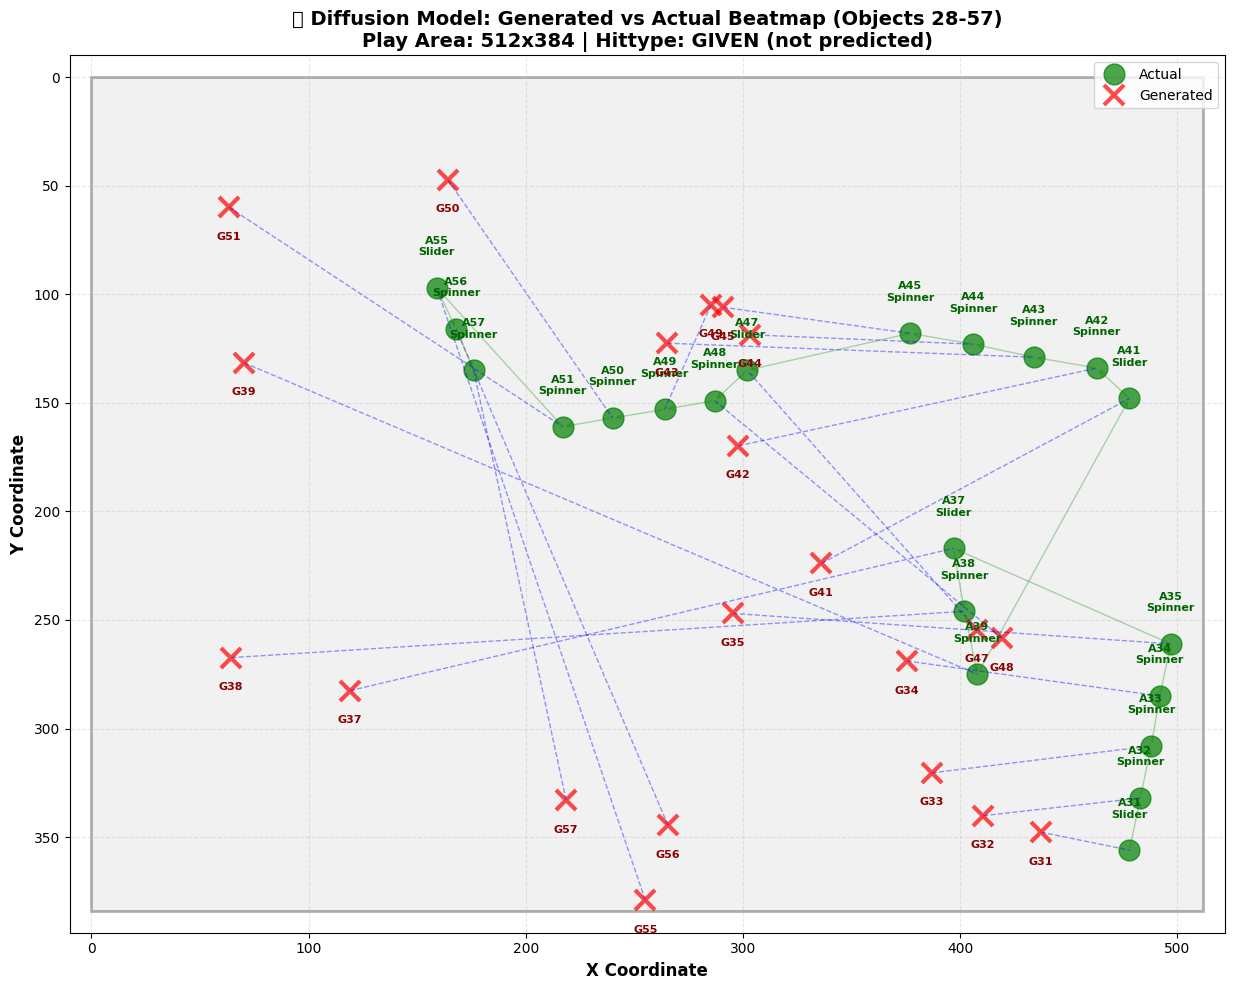


Detailed Comparison for Objects 28-57

Object 31 (HitType: Slider):
  Generated: ( 437.2,  347.7)
  Actual:    ( 478.0,  356.0)
  Error:     X=  40.8px, Y=   8.3px, Distance=  41.7px

Object 32 (HitType: Spinner):
  Generated: ( 410.6,  340.1)
  Actual:    ( 483.0,  332.0)
  Error:     X=  72.4px, Y=   8.1px, Distance=  72.9px

Object 33 (HitType: Spinner):
  Generated: ( 387.0,  320.4)
  Actual:    ( 488.0,  308.0)
  Error:     X= 101.0px, Y=  12.4px, Distance= 101.8px

Object 34 (HitType: Spinner):
  Generated: ( 375.4,  268.9)
  Actual:    ( 492.0,  285.0)
  Error:     X= 116.6px, Y=  16.1px, Distance= 117.7px

Object 35 (HitType: Spinner):
  Generated: ( 295.3,  247.0)
  Actual:    ( 497.0,  261.0)
  Error:     X= 201.7px, Y=  14.0px, Distance= 202.2px

Object 37 (HitType: Slider):
  Generated: ( 119.0,  282.5)
  Actual:    ( 397.0,  217.0)
  Error:     X= 278.0px, Y=  65.5px, Distance= 285.6px

Object 38 (HitType: Spinner):
  Generated: (  64.4,  267.3)
  Actual:    ( 402.0,  246

In [18]:
# -------------------------------------------------
# Visualize Generated vs Actual on 512x384 Play Area
# -------------------------------------------------

import matplotlib.pyplot as plt
import matplotlib.patches as patches

# ===== MODIFY THESE PARAMETERS =====
chunk_start = 27   # Starting index (0 for first object, 20 for next chunk, etc.)
chunk_size = 30    # Number of hit objects to visualize
# ====================================

chunk_end = min(chunk_start + chunk_size, length)
print(f"Visualizing objects {chunk_start+1} to {chunk_end} (Total available: {length})")

# Extract the chunk
gen_x_chunk = gen_x[chunk_start:chunk_end]
gen_y_chunk = gen_y[chunk_start:chunk_end]
actual_x_chunk = actual_x[chunk_start:chunk_end]
actual_y_chunk = actual_y[chunk_start:chunk_end]
hittype_chunk = hittypes_np[chunk_start:chunk_end]

# Create figure with play area
fig, ax = plt.subplots(figsize=(14, 10))

# Draw the play area (512x384)
rect = patches.Rectangle((0, 0), 512, 384, linewidth=2, edgecolor='black', facecolor='lightgray', alpha=0.3)
ax.add_patch(rect)

# Hit type names for display
hit_types = {0: 'Pad', 1: 'Normal', 2: 'Slider', 3: 'Spinner', 4: 'Combo', 5: 'Other'}

# Filter out padding (hittype 0)
valid_indices = [i for i in range(len(hittype_chunk)) if hittype_chunk[i] > 0]

# Plot actual positions (green circles)
for idx, i in enumerate(valid_indices):
    ax.plot(actual_x_chunk[i], actual_y_chunk[i], 'go', markersize=15, alpha=0.7, 
            label='Actual' if idx == 0 else '')
    ax.text(actual_x_chunk[i], actual_y_chunk[i] - 15, 
            f'A{chunk_start+i+1}\n{hit_types[hittype_chunk[i]]}', 
            ha='center', fontsize=8, color='darkgreen', fontweight='bold')

# Plot generated positions (red crosses)
for idx, i in enumerate(valid_indices):
    ax.plot(gen_x_chunk[i], gen_y_chunk[i], 'rx', markersize=15, markeredgewidth=3, alpha=0.7, 
            label='Generated' if idx == 0 else '')
    ax.text(gen_x_chunk[i], gen_y_chunk[i] + 15, 
            f'G{chunk_start+i+1}', 
            ha='center', fontsize=8, color='darkred', fontweight='bold')

# Draw lines connecting generated to actual (error visualization)
for i in valid_indices:
    ax.plot([gen_x_chunk[i], actual_x_chunk[i]], [gen_y_chunk[i], actual_y_chunk[i]], 
            'b--', alpha=0.4, linewidth=1)

# Draw sequence order (connecting actual positions)
valid_list = list(valid_indices)
for idx in range(len(valid_list) - 1):
    i, j = valid_list[idx], valid_list[idx+1]
    ax.annotate('', xy=(actual_x_chunk[j], actual_y_chunk[j]), 
                xytext=(actual_x_chunk[i], actual_y_chunk[i]),
                arrowprops=dict(arrowstyle='->', color='green', alpha=0.3, lw=1))

# Set plot properties
ax.set_xlim(-10, 522)
ax.set_ylim(-10, 394)
ax.set_xlabel('X Coordinate', fontsize=12, fontweight='bold')
ax.set_ylabel('Y Coordinate', fontsize=12, fontweight='bold')
ax.set_title(f'🌊 Diffusion Model: Generated vs Actual Beatmap (Objects {chunk_start+1}-{chunk_end})\nPlay Area: 512x384 | Hittype: GIVEN (not predicted)', 
             fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, linestyle='--')
ax.legend(loc='upper right', fontsize=10)
ax.set_aspect('equal')

# Invert y-axis to match osu! coordinate system (0,0 at top-left)
ax.invert_yaxis()

plt.tight_layout()
plt.show()

# Print detailed comparison for the chunk
print("\n" + "=" * 80)
print(f"Detailed Comparison for Objects {chunk_start+1}-{chunk_end}")
print("=" * 80)
for i in valid_indices:
    error_x = abs(gen_x_chunk[i] - actual_x_chunk[i])
    error_y = abs(gen_y_chunk[i] - actual_y_chunk[i])
    error_dist = np.sqrt(error_x**2 + error_y**2)
    
    print(f"\nObject {chunk_start+i+1} (HitType: {hit_types[hittype_chunk[i]]}):")
    print(f"  Generated: ({gen_x_chunk[i]:6.1f}, {gen_y_chunk[i]:6.1f})")
    print(f"  Actual:    ({actual_x_chunk[i]:6.1f}, {actual_y_chunk[i]:6.1f})")
    print(f"  Error:     X={error_x:6.1f}px, Y={error_y:6.1f}px, Distance={error_dist:6.1f}px")

print("=" * 80)
print("\n💡 Note: Hittype is GIVEN as input to the model (not predicted)")
print("   Model only generates x, y coordinates conditioned on hittype")


In [19]:
# -------------------------------------------------
# Generate Full Beatmap and Export to CSV (Load from File Paths)
# -------------------------------------------------

import pandas as pd
import json
device = 'cuda'
# Load best model
print("Loading trained model...")
checkpoint = torch.load('/kaggle/input/osu-diffusion/best_diffusion_model.pth', map_location=device)
diffusion_model.load_state_dict(checkpoint['model'])
diffusion_model.eval()
print(f"✅ Model loaded (Val Loss: {checkpoint['val_loss']:.6f})\n")

# ===== INPUT FILE PATHS =====
# Provide the base filename (without extension)
base_filename = "your_file_name"  # e.g., "song123" or "beatmap_abc"

# Full file paths
audio_file = f"{base_filename}.npy"           # Audio features
hyper_file = f"{base_filename}.json"          # Hyperparameters
beatmap_file = f"{base_filename}-b.npy"       # Actual beatmap (for comparison)

# Output CSV file
csv_filename = f"generated_{base_filename}.csv"

# Or use full paths:
audio_file = "/kaggle/input/mertosu/mert-preprocessed/51aef9602430c5b2d95f4cc1699f4faf.npy"
hyper_file = "/kaggle/input/mertosu/processed-hyperparam/51aef9602430c5b2d95f4cc1699f4faf-b.json"
beatmap_file = "/kaggle/input/mertosu/processed-beatmaps-unparseForm/51aef9602430c5b2d95f4cc1699f4faf-d.npy"
csv_filename = "generated_beatmap.csv"
# ============================

print("=" * 80)
print(f"🎵 Generating Full Beatmap from Files")
print("=" * 80)

print(f"\n📂 Loading files:")
print(f"   Audio: {audio_file}")
print(f"   Hyper: {hyper_file}")
print(f"   Beatmap: {beatmap_file}")

# Load audio features from file
print(f"\n📥 Loading data from files...")
audio_data = np.load(audio_file, allow_pickle=True)
if audio_data.dtype == object:
    audio_data = extract_audio_features(audio_data)
else:
    audio_data = np.asarray(audio_data, dtype=np.float32)
audio_data = np.nan_to_num(audio_data, nan=0.0, posinf=0.0, neginf=0.0)

# Load beatmap from file
beatmap_data = np.load(beatmap_file, allow_pickle=True)
beatmap_data = np.asarray(beatmap_data, dtype=np.float32)
beatmap_data = beatmap_data[:, [0, 1, 3]]  # Keep x, y, hittype
# Normalize x, y
beatmap_data[:, 0] = (beatmap_data[:, 0] / 512.0) * 2.0 - 1.0
beatmap_data[:, 1] = (beatmap_data[:, 1] / 384.0) * 2.0 - 1.0
beatmap_data = np.nan_to_num(beatmap_data, nan=0.0, posinf=0.0, neginf=0.0)

# Load hyperparameters from file
hyper_data = load_hyper_json(hyper_file)
hyper_data = np.nan_to_num(hyper_data, nan=0.0, posinf=0.0, neginf=0.0)

# Convert to tensors and add batch dimension
audio = torch.tensor(audio_data, dtype=torch.float32).unsqueeze(0).to(device)
actual_beatmap = torch.tensor(beatmap_data, dtype=torch.float32).unsqueeze(0).to(device)
hyper = torch.tensor(hyper_data, dtype=torch.float32).unsqueeze(0).to(device)
length = audio.shape[1]

print(f"   ✅ Audio shape: {audio.shape}")
print(f"   ✅ Beatmap shape: {actual_beatmap.shape}")
print(f"   ✅ Hyper shape: {hyper.shape}")

# Extract hittypes
actual_hittypes = actual_beatmap[:, :, 2].long()
actual_xy = actual_beatmap[:, :, :2]

print(f"\n📊 Sample Info:")
print(f"   Total Objects: {length}")
print(f"   Hyperparameters: {hyper[0].cpu().numpy()}")

# Generate full beatmap
print(f"\n🌊 Generating beatmap (1000 denoising steps)...")
generated_xy = sample_beatmap(
    diffusion_model, scheduler, 
    audio, hyper, actual_hittypes, 
    device
)

print(f"✅ Generation complete!")

# Denormalize coordinates
gen_xy_full = generated_xy[0, :length].cpu().numpy()
actual_xy_full = actual_xy[0, :length].cpu().numpy()
hittypes_full = actual_hittypes[0, :length].cpu().numpy()

# Convert from normalized [-1, 1] to pixel coordinates
gen_x_full = (gen_xy_full[:, 0] + 1) / 2.0 * 512
gen_y_full = (gen_xy_full[:, 1] + 1) / 2.0 * 384
actual_x_full = (actual_xy_full[:, 0] + 1) / 2.0 * 512
actual_y_full = (actual_xy_full[:, 1] + 1) / 2.0 * 384

# Filter out padding (hittype 0)
valid_mask = hittypes_full > 0
gen_x_valid = gen_x_full[valid_mask]
gen_y_valid = gen_y_full[valid_mask]
actual_x_valid = actual_x_full[valid_mask]
actual_y_valid = actual_y_full[valid_mask]
hittypes_valid = hittypes_full[valid_mask]

num_valid = len(gen_x_valid)

print(f"\n📈 Full Sequence Statistics:")
print(f"   Total positions (with padding): {length}")
print(f"   Valid positions (no padding):   {num_valid}")

# Calculate statistics
gen_distances = np.sqrt(np.diff(gen_x_valid)**2 + np.diff(gen_y_valid)**2)
actual_distances = np.sqrt(np.diff(actual_x_valid)**2 + np.diff(actual_y_valid)**2)

print(f"\n   Generated:")
print(f"      Avg Distance: {gen_distances.mean():.2f} px")
print(f"      Std Distance: {gen_distances.std():.2f} px")
print(f"      Min Distance: {gen_distances.min():.2f} px")
print(f"      Max Distance: {gen_distances.max():.2f} px")

print(f"\n   Actual:")
print(f"      Avg Distance: {actual_distances.mean():.2f} px")
print(f"      Std Distance: {actual_distances.std():.2f} px")
print(f"      Min Distance: {actual_distances.min():.2f} px")
print(f"      Max Distance: {actual_distances.max():.2f} px")

# Overall MSE
mse_full = np.mean((gen_xy_full[valid_mask] - actual_xy_full[valid_mask])**2)
print(f"\n   MSE (normalized): {mse_full:.6f}")

# Create DataFrame and save to CSV
beatmap_df = pd.DataFrame({
    'x': gen_x_valid,
    'y': gen_y_valid,
    'hittype': hittypes_valid.astype(int)
})

beatmap_df.to_csv(csv_filename, index=False)

print(f"\n💾 CSV File Saved:")
print(f"   Filename: {csv_filename}")
print(f"   Rows: {len(beatmap_df)}")
print(f"   Columns: x, y, hittype")

# Show first and last 10 rows
print(f"\n📋 First 10 Objects:")
print(beatmap_df.head(10).to_string(index=False))

print(f"\n📋 Last 10 Objects:")
print(beatmap_df.tail(10).to_string(index=False))

print("\n" + "=" * 80)
print(f"✅ Full beatmap exported to {csv_filename}")
print("=" * 80)


Loading trained model...
✅ Model loaded (Val Loss: 0.058091)

🎵 Generating Full Beatmap from Files

📂 Loading files:
   Audio: /kaggle/input/mertosu/mert-preprocessed/51aef9602430c5b2d95f4cc1699f4faf.npy
   Hyper: /kaggle/input/mertosu/processed-hyperparam/51aef9602430c5b2d95f4cc1699f4faf-b.json
   Beatmap: /kaggle/input/mertosu/processed-beatmaps-unparseForm/51aef9602430c5b2d95f4cc1699f4faf-d.npy

📥 Loading data from files...
   ✅ Audio shape: torch.Size([1, 705, 768])
   ✅ Beatmap shape: torch.Size([1, 705, 3])
   ✅ Hyper shape: torch.Size([1, 7])

📊 Sample Info:
   Total Objects: 705
   Hyperparameters: [  8.    4.    5.    8.    1.4   1.  120. ]

🌊 Generating beatmap (1000 denoising steps)...
  Denoising step 200/1000
  Denoising step 400/1000
  Denoising step 600/1000
  Denoising step 800/1000
  Denoising step 1000/1000
✅ Generation complete!

📈 Full Sequence Statistics:
   Total positions (with padding): 705
   Valid positions (no padding):   523

   Generated:
      Avg Distance

# **More adv** 

In [3]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import json
from scipy.interpolate import interp1d


# -------------------------------------------------
# JSON hyperparam loader
# -------------------------------------------------
def load_hyper_json(path):
    with open(path, "r") as f:
        data = json.load(f)

    if isinstance(data, dict):
        # deterministic key order → consistent feature vector
        data = [data[k] for k in sorted(data.keys())]

    return np.asarray(data, dtype=np.float32)


# -------------------------------------------------
# Extract features from weird audio format:
# each row = [timestamp, feature_vector]
# -------------------------------------------------
def extract_audio_features(obj_arr):
    """Extract audio features without timestamps"""
    result = []
    for row in obj_arr:
        features = row[1]  # Just the features, not timestamp
        result.append(features)
    return np.vstack(result).astype(np.float32)


# -------------------------------------------------
# Align audio to beatmap timestamps via interpolation
# -------------------------------------------------
def align_audio_to_beatmap(audio, beatmap_times, audio_times=None):
    """
    Interpolate audio features to match beatmap timestamps exactly.
    
    audio: shape (N_audio, D_audio) - audio features
    beatmap_times: timestamps from beatmap
    audio_times: optional audio timestamps (if available)
    
    Returns: aligned_audio with shape (len(beatmap_times), D_audio)
    """
    if audio_times is None:
        # If no timestamps, assume uniform spacing
        audio_times = np.linspace(0, beatmap_times[-1], len(audio))
    
    # Interpolate each audio feature dimension to beatmap timestamps
    aligned_features = np.zeros((len(beatmap_times), audio.shape[1]), dtype=np.float32)
    
    for feat_idx in range(audio.shape[1]):
        interpolator = interp1d(
            audio_times, 
            audio[:, feat_idx],
            kind='linear',
            bounds_error=False,
            fill_value='extrapolate'
        )
        aligned_features[:, feat_idx] = interpolator(beatmap_times)
    
    return aligned_features.astype(np.float32)


# -------------------------------------------------
# Compute Delta Features for Better Flow
# -------------------------------------------------
def compute_deltas(beatmap):
    """
    Compute spatial delta features (Δx, Δy) to capture movement patterns.
    
    Args:
        beatmap: (seq_len, 4) - [x, y, timestamp, hittype]
    
    Returns:
        spatial_deltas: (seq_len, 2) - [Δx, Δy] spatial movement
        first_position: (2,) - first absolute position [x0, y0]
    """
    seq_len = beatmap.shape[0]
    
    # Initialize spatial deltas
    spatial_deltas = np.zeros((seq_len, 2), dtype=np.float32)
    
    # Compute spatial deltas: position[i] - position[i-1]
    spatial_deltas[1:, 0] = beatmap[1:, 0] - beatmap[:-1, 0]  # Δx
    spatial_deltas[1:, 1] = beatmap[1:, 1] - beatmap[:-1, 1]  # Δy
    
    # First position has no previous - use zeros
    spatial_deltas[0] = [0.0, 0.0]
    
    # Store first absolute position (needed to reconstruct sequence)
    first_position = beatmap[0, :2].copy()  # Only x, y
    
    return spatial_deltas, first_position


class OsuDataset(Dataset):
    def __init__(self, df, use_deltas=True):
        """
        Args:
            df: DataFrame with file paths
            use_deltas: If True, return delta features (Δx, Δy) for better flow learning
        """
        self.df = df
        self.use_deltas = use_deltas

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # -------------------------------------------------
        # AUDIO: Extract features without timestamps
        # -------------------------------------------------
        audio_raw = np.load(row["audio_feature_path"], allow_pickle=True)
        if audio_raw.dtype == object:
            # Extract timestamps separately for alignment
            audio_times = np.array([r[0] for r in audio_raw], dtype=np.float32)
            audio = extract_audio_features(audio_raw)
        else:
            audio_times = None
            audio = np.asarray(audio_raw, dtype=np.float32)
        
        # Clean audio data
        audio = np.nan_to_num(audio, nan=0.0, posinf=0.0, neginf=0.0)

        # -------------------------------------------------
        # BEATMAP: Load and normalize
        # -------------------------------------------------
        beatmap = np.load(row["beatmap_path"], allow_pickle=True)
        beatmap = np.asarray(beatmap, dtype=np.float32)

        # Normalize x,y to [-1, 1]
        beatmap[:, 0] = (beatmap[:, 0] / 512.0) * 2.0 - 1.0  # x
        beatmap[:, 1] = (beatmap[:, 1] / 384.0) * 2.0 - 1.0  # y
        # timestamp (column 2) and hittype (column 3) stay as-is
        
        # Clean beatmap data
        beatmap = np.nan_to_num(beatmap, nan=0.0, posinf=0.0, neginf=0.0)

        # -------------------------------------------------
        # ALIGN AUDIO TO BEATMAP TIMESTAMPS
        # -------------------------------------------------
        beatmap_times = beatmap[:, 2]
        audio = align_audio_to_beatmap(audio, beatmap_times, audio_times)

        # -------------------------------------------------
        # COMPUTE DELTA FEATURES (for better flow)
        # -------------------------------------------------
        if self.use_deltas:
            spatial_deltas, first_pos = compute_deltas(beatmap)
            
            result = {
                "audio": torch.tensor(audio, dtype=torch.float32),
                "beatmap_deltas": torch.tensor(spatial_deltas, dtype=torch.float32),  # [Δx, Δy]
                "hittype": torch.tensor(beatmap[:, 3], dtype=torch.long),
                "first_position": torch.tensor(first_pos, dtype=torch.float32),  # [x0, y0]
                "hyper": torch.tensor(load_hyper_json(row["hyper_path"]), dtype=torch.float32)
            }
        else:
            # Original format (absolute positions)
            result = {
                "audio": torch.tensor(audio, dtype=torch.float32),
                "beatmap": torch.tensor(beatmap, dtype=torch.float32),
                "hyper": torch.tensor(load_hyper_json(row["hyper_path"]), dtype=torch.float32)
            }

        return result


# -------------------------------------------------
# Collate function for DELTA-based dataset
# -------------------------------------------------
def collate_fn_deltas(batch):
    """
    Collate function for delta-based dataset.
    Pads all sequences to batch max length.
    
    Returns:
        - audio: (batch, max_len, D) - padded audio features
        - beatmap_deltas: (batch, max_len, 2) - padded [Δx, Δy]
        - hittype: (batch, max_len) - padded hit types
        - first_position: (batch, 2) - first [x0, y0]
        - lengths: (batch,) - original sequence lengths
        - hyper: (batch, 7) - hyperparameters
    """
    audios = [item["audio"] for item in batch]
    beatmap_deltas = [item["beatmap_deltas"] for item in batch]
    hittypes = [item["hittype"] for item in batch]
    first_positions = [item["first_position"] for item in batch]
    hypers = [item["hyper"] for item in batch]

    # Get max length
    audio_lens = [a.shape[0] for a in audios]
    max_len = max(audio_lens)
    audio_dim = audios[0].shape[1]

    # Pad audio
    padded_audio = torch.zeros(len(batch), max_len, audio_dim)
    for i, a in enumerate(audios):
        padded_audio[i, :a.shape[0]] = a

    # Pad spatial deltas [Δx, Δy]
    padded_deltas = torch.zeros(len(batch), max_len, 2)
    for i, d in enumerate(beatmap_deltas):
        padded_deltas[i, :d.shape[0]] = d

    # Pad hittypes
    padded_hittypes = torch.zeros(len(batch), max_len, dtype=torch.long)
    for i, h in enumerate(hittypes):
        padded_hittypes[i, :h.shape[0]] = h

    # Stack first positions and hypers
    first_pos_tensor = torch.stack(first_positions)
    hyper_tensor = torch.stack(hypers)

    return {
        "audio": padded_audio,
        "beatmap_deltas": padded_deltas,
        "hittype": padded_hittypes,
        "first_position": first_pos_tensor,
        "lengths": torch.tensor(audio_lens),
        "hyper": hyper_tensor,
    }


# -------------------------------------------------
# Collate function: pads sequences to batch max length
# -------------------------------------------------
def collate_fn(batch):
    audios = [item["audio"] for item in batch]
    beatmaps = [item["beatmap"] for item in batch]
    hypers = [item["hyper"] for item in batch]

    # Get max length across BOTH audio and beatmap
    audio_lens = [a.shape[0] for a in audios]
    bm_lens = [b.shape[0] for b in beatmaps]
    max_len = max(max(audio_lens), max(bm_lens))
    
    audio_dim = audios[0].shape[1]
    bm_dim = beatmaps[0].shape[1]

    # Pad both to same max length
    padded_audio = torch.zeros(len(batch), max_len, audio_dim)
    for i, a in enumerate(audios):
        padded_audio[i, :a.shape[0]] = a

    padded_bm = torch.zeros(len(batch), max_len, bm_dim)
    for i, b in enumerate(beatmaps):
        padded_bm[i, :b.shape[0]] = b

    hyper_tensor = torch.stack(hypers)

    return {
        "audio": padded_audio,
        "audio_lengths": torch.tensor(audio_lens),
        "beatmap": padded_bm,
        "beatmap_lengths": torch.tensor(bm_lens),
        "hyper": hyper_tensor,
    }


# -------------------------------------------------
# Dataloader factory
# -------------------------------------------------
def make_dataloader(df, batch_size=8, shuffle=True, use_deltas=True):
    dataset = OsuDataset(df, use_deltas=use_deltas)
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        collate_fn=collate_fn_deltas if use_deltas else collate_fn,
        num_workers=2,
    )
    return dataset, loader

print("✓ Dataset with DELTA features!")
print("✓ Spatial deltas: [Δx, Δy] - captures movement and flow")
print("✓ Timestamps removed from features (delta time is same for song)")
print("✓ Absolute positions reconstructed via cumulative sum during generation")


✓ Dataset with DELTA features!
✓ Spatial deltas: [Δx, Δy] - captures movement and flow
✓ Timestamps removed from features (delta time is same for song)
✓ Absolute positions reconstructed via cumulative sum during generation


In [4]:
# Create DataLoader with DELTA features
dataset, loader = make_dataloader(df, batch_size=8, shuffle=True, use_deltas=True)

print(f"Dataset size: {len(dataset)}")
print(f"\nLoading first batch with DELTA features...")

# Get one batch to verify shapes
batch = next(iter(loader))

print(f"\nBatch structure:")
print(f"  Audio shape: {batch['audio'].shape}")  # (batch, seq_len, D)
print(f"  Deltas shape: {batch['beatmap_deltas'].shape}")  # (batch, seq_len, 2) → [Δx, Δy]
print(f"  Hittype shape: {batch['hittype'].shape}")  # (batch, seq_len)
print(f"  First position shape: {batch['first_position'].shape}")  # (batch, 2) → [x0, y0]
print(f"  Hyper shape: {batch['hyper'].shape}")  # (batch, n_hyperparams)
print(f"  Lengths: {batch['lengths']}")

print(f"\n✅ Using DELTA features [Δx, Δy] for better flow learning!")
print(f"✅ Timestamps removed - delta time is same for song")
print(f"✅ Ready for improved Transformer+Diffusion model!")

# Show sample deltas from first item in batch
print(f"\n--- Sample deltas from first item (first 5 steps) ---")
deltas = batch['beatmap_deltas'][0, :5]
print(f"{'Step':<6} | {'Δx':>10} | {'Δy':>10}")
print("-" * 32)
for i in range(5):
    print(f"{i:<6} | {deltas[i,0]:>10.4f} | {deltas[i,1]:>10.4f}")

print(f"\n--- First position (reconstruction anchor) ---")
first_pos = batch['first_position'][0]
print(f"x0={first_pos[0]:.4f}, y0={first_pos[1]:.4f}")

# DEBUG: Check what's actually in the raw data
print(f"\n🔍 DEBUG: Checking raw beatmap data...")
sample_idx = 0
row = df.iloc[sample_idx]
beatmap_raw = np.load(row["beatmap_path"], allow_pickle=True)
beatmap_raw = np.asarray(beatmap_raw, dtype=np.float32)
print(f"Raw beatmap shape: {beatmap_raw.shape}")
print(f"First 5 rows (before normalization):")
print(f"{'Idx':<4} | {'x':>10} | {'y':>10} | {'timestamp':>12} | {'hittype':>8}")
print("-" * 55)
for i in range(min(5, len(beatmap_raw))):
    print(f"{i:<4} | {beatmap_raw[i,0]:>10.2f} | {beatmap_raw[i,1]:>10.2f} | {beatmap_raw[i,2]:>12.2f} | {beatmap_raw[i,3]:>8.0f}")

# Check normalized beatmap
beatmap_norm = beatmap_raw.copy()
beatmap_norm[:, 0] = (beatmap_norm[:, 0] / 512.0) * 2.0 - 1.0  # x
beatmap_norm[:, 1] = (beatmap_norm[:, 1] / 384.0) * 2.0 - 1.0  # y
print(f"\nAfter normalization (first 5 rows):")
print(f"{'Idx':<4} | {'x (norm)':>12} | {'y (norm)':>12}")
print("-" * 35)
for i in range(min(5, len(beatmap_norm))):
    print(f"{i:<4} | {beatmap_norm[i,0]:>12.6f} | {beatmap_norm[i,1]:>12.6f}")

# Manually compute deltas to verify
manual_deltas = np.zeros((len(beatmap_norm), 2), dtype=np.float32)
manual_deltas[1:, 0] = beatmap_norm[1:, 0] - beatmap_norm[:-1, 0]  # Δx
manual_deltas[1:, 1] = beatmap_norm[1:, 1] - beatmap_norm[:-1, 1]  # Δy
print(f"\nManually computed deltas (first 5):")
print(f"{'Idx':<4} | {'Δx':>12} | {'Δy':>12}")
print("-" * 35)
for i in range(min(5, len(manual_deltas))):
    print(f"{i:<4} | {manual_deltas[i,0]:>12.6f} | {manual_deltas[i,1]:>12.6f}")



Dataset size: 6008

Loading first batch with DELTA features...

Batch structure:
  Audio shape: torch.Size([8, 1190, 768])
  Deltas shape: torch.Size([8, 1190, 2])
  Hittype shape: torch.Size([8, 1190])
  First position shape: torch.Size([8, 2])
  Hyper shape: torch.Size([8, 7])
  Lengths: tensor([1144,  989, 1190, 1086,  902, 1173, 1089,  833])

✅ Using DELTA features [Δx, Δy] for better flow learning!
✅ Timestamps removed - delta time is same for song
✅ Ready for improved Transformer+Diffusion model!

--- Sample deltas from first item (first 5 steps) ---
Step   |         Δx |         Δy
--------------------------------
0      |     0.0000 |     0.0000
1      |     0.1328 |    -0.0365
2      |     0.1523 |     0.0000
3      |    -0.6328 |    -0.7812
4      |     0.9609 |     0.8542

--- First position (reconstruction anchor) ---
x0=-0.6523, y0=-0.1823

🔍 DEBUG: Checking raw beatmap data...
Raw beatmap shape: (1103, 4)
First 5 rows (before normalization):
Idx  |          x |          y

In [5]:
# -------------------------------------------------
# Train/Validation/Test Split with DELTA features
# -------------------------------------------------
from sklearn.model_selection import train_test_split

# First split: train vs temp (val+test)
train_df, temp_df = train_test_split(
    df, test_size=0.2, random_state=42
)

# Second split: val vs test (each 10% of original)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42
)

# Create dataloaders with DELTA features
train_dataset, train_loader = make_dataloader(train_df, batch_size=8, shuffle=True, use_deltas=True)
val_dataset, val_loader = make_dataloader(val_df, batch_size=8, shuffle=False, use_deltas=True)
test_dataset, test_loader = make_dataloader(test_df, batch_size=8, shuffle=False, use_deltas=True)

print(f"✅ Train samples: {len(train_dataset)}")
print(f"✅ Validation samples: {len(val_dataset)}")
print(f"✅ Test samples: {len(test_dataset)}")
print(f"\n✅ Using DELTA features [Δx, Δy]")
print("✅ Timestamps removed from model")
print("✅ Ready to train with improved architecture!")


✅ Train samples: 4806
✅ Validation samples: 601
✅ Test samples: 601

✅ Using DELTA features [Δx, Δy]
✅ Timestamps removed from model
✅ Ready to train with improved architecture!


In [6]:
# -------------------------------------------------
# IMPROVED Dual-Encoder Diffusion Model with Delta Prediction
# -------------------------------------------------
import torch
import torch.nn as nn
import numpy as np

class SinusoidalTimeEmbedding(nn.Module):
    """Embed diffusion timestep (which denoising step we're at)"""
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    
    def forward(self, t):
        device = t.device
        half_dim = self.dim // 2
        embeddings = np.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = t[:, None] * embeddings[None, :]
        embeddings = torch.cat([torch.sin(embeddings), torch.cos(embeddings)], dim=-1)
        return embeddings


class DualEncoderDiffusionModel(nn.Module):
    """
    IMPROVED Dual-Encoder Architecture with causal conditioning:
    
    1. Bidirectional Audio Encoder: Processes full audio with NO causal mask
       - Audio is external INPUT condition, can see all timesteps
       - Learns global rhythm and musical structure
    
    2. Causal Beatmap Decoder: Generates deltas autoregressively
       - Cross-attends to audio encoding (full song context)
       - Self-attends with CAUSAL MASK (no future leakage!)
       - Predicts spatial deltas [Δx, Δy]
    
    Inputs:
        - noisy_deltas: (batch, seq_len, 2) - current noisy [Δx, Δy] being denoised
        - timestep: (batch,) - diffusion timestep
        - audio: (batch, seq_len, D) - FULL audio features (INPUT)
        - hyper: (batch, 7) - hyperparameters for song (INPUT)
        - prev_spatial_deltas: (batch, seq_len, 2) - SHIFTED previous [Δx, Δy]
        - current_hittype: (batch, seq_len) - current hittype (INPUT - known)
        - prev_hittypes: (batch, seq_len) - SHIFTED previous hittypes
    
    Output:
        - predicted_noise: (batch, seq_len, 2) - noise for [Δx, Δy]
    """
    def __init__(
        self,
        audio_dim=768,
        hyper_dim=7,
        delta_dim=2,  # Δx, Δy spatial
        hittype_embed_dim=32,
        time_embed_dim=64,
        d_model=256,
        nhead=8,
        num_audio_layers=6,  # Bidirectional audio encoder
        num_decoder_layers=8,  # Causal beatmap decoder
        dropout=0.1,
        num_hittype_classes=6
    ):
        super().__init__()
        
        self.d_model = d_model
        
        # ============================================================
        # AUDIO ENCODER (Bidirectional - sees full context)
        # This is INPUT - no causal restriction needed
        # ============================================================
        self.audio_proj = nn.Linear(audio_dim, d_model)
        self.audio_pos_encoder = PositionalEncoding(d_model, max_len=5000)
        
        audio_encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=1024,
            dropout=dropout,
            batch_first=True,
            activation='gelu'
        )
        self.audio_encoder = nn.TransformerEncoder(audio_encoder_layer, num_layers=num_audio_layers)
        
        # ============================================================
        # BEATMAP DECODER (Causal - autoregressive)
        # ============================================================
        
        # Diffusion timestep embedding
        self.time_embed = nn.Sequential(
            SinusoidalTimeEmbedding(time_embed_dim),
            nn.Linear(time_embed_dim, time_embed_dim * 2),
            nn.SiLU(),
            nn.Linear(time_embed_dim * 2, time_embed_dim)
        )
        
        # Project noisy spatial deltas (current Δx, Δy being denoised)
        self.delta_proj = nn.Linear(delta_dim, d_model)
        
        # Project hyperparameters (INPUT - full song)
        self.hyper_proj = nn.Linear(hyper_dim, 64)
        
        # Project PREVIOUS spatial deltas [Δx, Δy] (SHIFTED - causal)
        self.prev_spatial_delta_proj = nn.Sequential(
            nn.Linear(delta_dim, d_model),
            nn.LayerNorm(d_model),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        
        # Embed CURRENT hittype (INPUT - known at generation time)
        self.current_hittype_embedding = nn.Embedding(num_hittype_classes, hittype_embed_dim)
        
        # Embed PREVIOUS hittypes (SHIFTED - causal)
        self.prev_hittype_embedding = nn.Embedding(num_hittype_classes, hittype_embed_dim)
        
        # Combine ALL decoder inputs
        # noisy_deltas + hyper + prev_spatial + current_hittype + prev_hittype + diffusion_t
        combined_dim = d_model + 64 + d_model + hittype_embed_dim + hittype_embed_dim + time_embed_dim
        self.decoder_input_combine = nn.Linear(combined_dim, d_model)
        
        # Positional encoding for decoder
        self.decoder_pos_encoder = PositionalEncoding(d_model, max_len=5000)
        
        # Causal Transformer Decoder with Cross-Attention to Audio
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=1024,
            dropout=dropout,
            batch_first=True,
            activation='gelu'
        )
        self.beatmap_decoder = nn.TransformerDecoder(decoder_layer, num_layers=num_decoder_layers)
        
        # Output: predict the noise to remove from spatial deltas [Δx, Δy]
        self.noise_pred = nn.Sequential(
            nn.Linear(d_model, 256),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.SiLU(),
            nn.Linear(128, delta_dim)  # Output: noise for [Δx, Δy]
        )
    
    def _generate_causal_mask(self, seq_len, device):
        """
        Generate causal mask: position i can only attend to positions 0..i
        This PREVENTS future leakage in beatmap decoder self-attention!
        """
        mask = torch.triu(torch.ones(seq_len, seq_len, device=device), diagonal=1)
        mask = mask.masked_fill(mask == 1, float('-inf'))
        return mask
    
    def forward(self, noisy_deltas, timestep, audio, hyper, 
                prev_spatial_deltas,
                current_hittype, prev_hittypes):
        """
        Predict noise in noisy_deltas at given timestep.
        
        Args:
            noisy_deltas: (batch, seq_len, 2) - current noisy [Δx, Δy]
            timestep: (batch,) - diffusion timestep
            audio: (batch, seq_len, D) - FULL audio features
            hyper: (batch, 7) - hyperparameters
            prev_spatial_deltas: (batch, seq_len, 2) - SHIFTED previous [Δx, Δy]
            current_hittype: (batch, seq_len) - current hittype
            prev_hittypes: (batch, seq_len) - SHIFTED previous hittypes
        
        Returns:
            predicted_noise: (batch, seq_len, 2) - noise for [Δx, Δy]
        """
        batch_size, seq_len, _ = noisy_deltas.shape
        device = noisy_deltas.device
        
        # ============================================================
        # STEP 1: Encode Audio (Bidirectional - full context)
        # This is INPUT - sees entire song
        # ============================================================
        audio_emb = self.audio_proj(audio)  # (batch, seq_len, d_model)
        audio_emb = self.audio_pos_encoder(audio_emb)
        audio_encoded = self.audio_encoder(audio_emb)  # (batch, seq_len, d_model)
        
        # ============================================================
        # STEP 2: Prepare Decoder Inputs
        # ============================================================
        
        # Diffusion timestep embedding (expand to sequence)
        t_emb = self.time_embed(timestep)  # (batch, time_embed_dim)
        t_emb = t_emb.unsqueeze(1).expand(-1, seq_len, -1)
        
        # Project noisy spatial deltas being denoised
        delta_emb = self.delta_proj(noisy_deltas)
        
        # Project hyperparameters (INPUT - same for whole song)
        hyper_emb = self.hyper_proj(hyper)
        hyper_emb = hyper_emb.unsqueeze(1).expand(-1, seq_len, -1)
        
        # Project PREVIOUS spatial deltas (SHIFTED - causal)
        prev_spatial_emb = self.prev_spatial_delta_proj(prev_spatial_deltas)
        
        # Embed CURRENT hittype (INPUT - known at generation time)
        current_hittype_emb = self.current_hittype_embedding(current_hittype)
        
        # Embed PREVIOUS hittypes (SHIFTED - causal)
        prev_hittype_emb = self.prev_hittype_embedding(prev_hittypes)
        
        # Combine ALL decoder inputs
        combined = torch.cat([
            delta_emb,           # noisy deltas being denoised
            hyper_emb,           # hyperparameters (INPUT)
            prev_spatial_emb,    # previous spatial deltas (SHIFTED - causal)
            current_hittype_emb, # current hittype (INPUT - known)
            prev_hittype_emb,    # previous hittypes (SHIFTED - causal)
            t_emb                # diffusion timestep
        ], dim=-1)
        
        combined = self.decoder_input_combine(combined)
        combined = self.decoder_pos_encoder(combined)
        
        # ============================================================
        # STEP 3: Decode with Cross-Attention to Audio
        # CAUSAL MASK ensures position i only sees 0..i in self-attention
        # ============================================================
        
        causal_mask = self._generate_causal_mask(seq_len, device)
        
        decoded = self.beatmap_decoder(
            tgt=combined,              # Decoder input
            memory=audio_encoded,      # Audio encoding (full context - INPUT)
            tgt_mask=causal_mask       # CAUSAL mask on self-attention
        )
        
        # ============================================================
        # STEP 4: Predict Noise for Spatial Deltas
        # ============================================================
        predicted_noise = self.noise_pred(decoded)
        
        return predicted_noise


class DiffusionScheduler:
    """
    Manages noise schedule for diffusion process
    Beta schedule: how much noise to add at each step
    """
    def __init__(self, num_timesteps=1000, beta_start=1e-4, beta_end=0.02):
        self.num_timesteps = num_timesteps
        
        # Linear beta schedule
        self.betas = torch.linspace(beta_start, beta_end, num_timesteps)
        self.alphas = 1.0 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, dim=0)
        
        # For sampling
        self.sqrt_alphas_cumprod = torch.sqrt(self.alphas_cumprod)
        self.sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - self.alphas_cumprod)
        
    def add_noise(self, deltas, timestep, noise=None):
        """
        Add noise to deltas at given timestep (forward process)
        """
        if noise is None:
            noise = torch.randn_like(deltas)
        
        # Move timestep to CPU for indexing, then move result to deltas device
        timestep_cpu = timestep.cpu()
        sqrt_alpha_prod = self.sqrt_alphas_cumprod[timestep_cpu].to(deltas.device)
        sqrt_one_minus_alpha_prod = self.sqrt_one_minus_alphas_cumprod[timestep_cpu].to(deltas.device)
        
        # Reshape for broadcasting
        sqrt_alpha_prod = sqrt_alpha_prod.view(-1, 1, 1)
        sqrt_one_minus_alpha_prod = sqrt_one_minus_alpha_prod.view(-1, 1, 1)
        
        noisy_deltas = sqrt_alpha_prod * deltas + sqrt_one_minus_alpha_prod * noise
        
        return noisy_deltas, noise
    
    def denoise_step(self, noisy_deltas, timestep, predicted_noise):
        """
        Remove predicted noise (reverse process / sampling)
        """
        device = noisy_deltas.device
        alpha = self.alphas[timestep].to(device)
        alpha_cumprod = self.alphas_cumprod[timestep].to(device)
        beta = self.betas[timestep].to(device)
        
        sqrt_alpha_cumprod = torch.sqrt(alpha_cumprod)
        sqrt_one_minus_alpha_cumprod = torch.sqrt(1.0 - alpha_cumprod)
        
        # Predict clean deltas
        pred_deltas = (noisy_deltas - sqrt_one_minus_alpha_cumprod * predicted_noise) / sqrt_alpha_cumprod
        
        # Clamp deltas to reasonable range
        pred_deltas = torch.clamp(pred_deltas, -2.0, 2.0)
        
        if timestep > 0:
            noise = torch.randn_like(noisy_deltas)
            prev_alpha_cumprod = self.alphas_cumprod[timestep - 1].to(device)
            
            coef1 = beta * torch.sqrt(prev_alpha_cumprod) / (1.0 - alpha_cumprod)
            coef2 = (1.0 - prev_alpha_cumprod) * torch.sqrt(alpha) / (1.0 - alpha_cumprod)
            
            posterior_mean = coef1 * pred_deltas + coef2 * noisy_deltas
            posterior_variance = beta * (1.0 - prev_alpha_cumprod) / (1.0 - alpha_cumprod)
            
            denoised = posterior_mean + torch.sqrt(posterior_variance) * noise
        else:
            denoised = pred_deltas
        
        return denoised


print("=" * 80)
print("✅ IMPROVED Dual-Encoder Diffusion Model!")


✅ IMPROVED Dual-Encoder Diffusion Model!


In [7]:
# -------------------------------------------------
# Shared Utilities for All Models
# -------------------------------------------------
import torch
import torch.nn as nn
import math

class PositionalEncoding(nn.Module):
    """Add positional information to sequences"""
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))  # (1, max_len, d_model)
    
    def forward(self, x):
        # Dynamically handle any sequence length
        seq_len = x.size(1)
        if seq_len > self.pe.size(1):
            # If sequence is longer than max_len, extend positional encoding on the fly
            device = x.device
            max_len = seq_len + 1000  # Add buffer
            pe = torch.zeros(max_len, x.size(-1), device=device)
            position = torch.arange(0, max_len, dtype=torch.float, device=device).unsqueeze(1)
            d_model = x.size(-1)
            div_term = torch.exp(torch.arange(0, d_model, 2, device=device).float() * (-math.log(10000.0) / d_model))
            pe[:, 0::2] = torch.sin(position * div_term)
            pe[:, 1::2] = torch.cos(position * div_term)
            self.pe = pe.unsqueeze(0)
        
        return x + self.pe[:, :seq_len]

print("✓ Shared utilities loaded (PositionalEncoding)")


✓ Shared utilities loaded (PositionalEncoding)


In [8]:
# -------------------------------------------------
# Test Data Loading with Delta Features
# -------------------------------------------------

print("🔍 Testing Delta-based Data Loading...\n")

# Load one batch to verify delta computation
test_batch = next(iter(train_loader))

print(f"Batch structure:")
print(f"  Audio shape: {test_batch['audio'].shape}")  # (batch, seq_len, D)
print(f"  Deltas shape: {test_batch['beatmap_deltas'].shape}")  # (batch, seq_len, 2) → [Δx, Δy]
print(f"  Hittype shape: {test_batch['hittype'].shape}")  # (batch, seq_len)
print(f"  First position shape: {test_batch['first_position'].shape}")  # (batch, 2)
print(f"  Hyper shape: {test_batch['hyper'].shape}")  # (batch, 7)
print(f"  Lengths: {test_batch['lengths']}")

# Show sample deltas from first item
print(f"\n--- Sample deltas from first item (first 10 steps) ---")
deltas = test_batch['beatmap_deltas'][0, :10].cpu().numpy()
print(f"{'Step':<6} | {'Δx':>10} | {'Δy':>10}")
print("-" * 32)
for i in range(min(10, len(deltas))):
    print(f"{i:<6} | {deltas[i,0]:>10.4f} | {deltas[i,1]:>10.4f}")

print(f"\n--- First position (for reconstruction) ---")
first_pos = test_batch['first_position'][0].cpu().numpy()
print(f"x0: {first_pos[0]:.4f}, y0: {first_pos[1]:.4f}")

# Verify reconstruction
length = test_batch['lengths'][0].item()
deltas_full = test_batch['beatmap_deltas'][0, :length].cpu().numpy()

reconstructed = np.zeros((length, 2))
reconstructed[0] = first_pos[:2]

for i in range(1, length):
    reconstructed[i] = reconstructed[i-1] + deltas_full[i]

print(f"\nReconstructed first 5 positions:")
print(f"{'Step':<6} | {'x':>10} | {'y':>10}")
print("-" * 28)
for i in range(min(5, length)):
    print(f"{i:<6} | {reconstructed[i,0]:>10.4f} | {reconstructed[i,1]:>10.4f}")

print(f"\n✅ Delta features working correctly!")
print(f"✅ Ready for improved diffusion training!")
print("=" * 80)


🔍 Testing Delta-based Data Loading...

Batch structure:
  Audio shape: torch.Size([8, 1244, 768])
  Deltas shape: torch.Size([8, 1244, 2])
  Hittype shape: torch.Size([8, 1244])
  First position shape: torch.Size([8, 2])
  Hyper shape: torch.Size([8, 7])
  Lengths: tensor([1193, 1183, 1158, 1063, 1112,  926, 1244, 1209])

--- Sample deltas from first item (first 10 steps) ---
Step   |         Δx |         Δy
--------------------------------
0      |     0.0000 |     0.0000
1      |    -0.4375 |    -0.1667
2      |     0.0000 |     0.0000
3      |     0.0000 |     0.0000
4      |     0.4375 |     1.0000
5      |    -0.4375 |    -1.0000
6      |     0.0000 |     0.0000
7      |     0.0000 |     0.0000
8      |     0.4375 |     1.0000
9      |    -0.4375 |    -1.0000

--- First position (for reconstruction) ---
x0: -0.5625, y0: -0.8333

Reconstructed first 5 positions:
Step   |          x |          y
----------------------------
0      |    -0.5625 |    -0.8333
1      |    -1.0000 |    -

In [11]:
# -------------------------------------------------
# IMPROVED Diffusion Training with Delta Prediction
# -------------------------------------------------

def create_shifted_spatial_deltas(spatial_deltas):
    """
    Create shifted SPATIAL deltas [Δx, Δy] for causal conditioning.
    Position i gets previous spatial deltas [0..i-1] as input.
    Position 0 gets zeros (no previous output).
    
    Args:
        spatial_deltas: (batch, seq_len, 2) - target spatial deltas [Δx, Δy]
    
    Returns:
        shifted: (batch, seq_len, 2) - shifted by 1, with zeros at start
    """
    batch_size, seq_len, dim = spatial_deltas.shape
    shifted = torch.zeros_like(spatial_deltas)
    shifted[:, 1:, :] = spatial_deltas[:, :-1, :]  # Shift right by 1
    return shifted


def create_shifted_hittypes(hittypes):
    """
    Create shifted hittypes for causal conditioning.
    Position i gets previous hittypes [0..i-1] as input.
    Position 0 gets zero (padding/no-hit class).
    
    Args:
        hittypes: (batch, seq_len) - target hittypes (integer class labels)
    
    Returns:
        shifted: (batch, seq_len) - shifted by 1, with 0 at start
    """
    batch_size, seq_len = hittypes.shape
    shifted = torch.zeros_like(hittypes)
    shifted[:, 1:] = hittypes[:, :-1]  # Shift right by 1
    return shifted


def train_diffusion_epoch(model, scheduler, loader, optimizer, device):
    """
    Train diffusion model for one epoch with causal conditioning.
    """
    model.train()
    total_loss = 0
    
    for batch_idx, batch in enumerate(loader):
        audio = batch['audio'].to(device)
        spatial_deltas = batch['beatmap_deltas'].to(device)  # (batch, seq, 2) = [Δx, Δy]
        hittypes = batch['hittype'].to(device)
        hyper = batch['hyper'].to(device)
        lengths = batch['lengths']
        
        batch_size = audio.size(0)
        
        # Create SHIFTED inputs for causal conditioning (teacher forcing)
        prev_spatial_deltas = create_shifted_spatial_deltas(spatial_deltas)  # [Δx, Δy] shifted
        prev_hittypes = create_shifted_hittypes(hittypes)  # hittypes shifted
        
        optimizer.zero_grad()
        
        # Sample random timesteps
        timesteps = torch.randint(
            0, scheduler.num_timesteps, 
            (batch_size,), 
            device=device
        ).long()
        
        # Add noise to clean spatial deltas
        noise = torch.randn_like(spatial_deltas)
        noisy_deltas, noise = scheduler.add_noise(spatial_deltas, timesteps, noise)
        
        # Predict the noise
        predicted_noise = model(
            noisy_deltas=noisy_deltas,
            timestep=timesteps,
            audio=audio,
            hyper=hyper,
            prev_spatial_deltas=prev_spatial_deltas,
            current_hittype=hittypes,
            prev_hittypes=prev_hittypes
        )
        
        # Loss: MSE between predicted and actual noise
        # Mask out padding
        mask = torch.zeros(batch_size, audio.size(1), dtype=torch.bool, device=device)
        for i, length in enumerate(lengths):
            mask[i, :length] = True
        mask = mask.unsqueeze(-1).float()  # (batch, seq_len, 1)
        
        loss = ((predicted_noise - noise) ** 2 * mask).sum() / (mask.sum() * 2 + 1e-8)
        
        # Backward
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        total_loss += loss.item()
        
        if (batch_idx + 1) % 50 == 0:
            print(f"  Batch {batch_idx+1}/{len(loader)} - Loss: {loss.item():.6f}")
    
    return total_loss / len(loader)


@torch.no_grad()
def validate_diffusion(model, scheduler, loader, device):
    """
    Validate diffusion model with causal conditioning.
    """
    model.eval()
    total_loss = 0
    
    for batch in loader:
        audio = batch['audio'].to(device)
        spatial_deltas = batch['beatmap_deltas'].to(device)  # (batch, seq, 2) = [Δx, Δy]
        hittypes = batch['hittype'].to(device)
        hyper = batch['hyper'].to(device)
        lengths = batch['lengths']
        
        batch_size = audio.size(0)
        
        # Create SHIFTED inputs for causal conditioning
        prev_spatial_deltas = create_shifted_spatial_deltas(spatial_deltas)
        prev_hittypes = create_shifted_hittypes(hittypes)
        
        # Sample random timesteps
        timesteps = torch.randint(
            0, scheduler.num_timesteps, 
            (batch_size,), 
            device=device
        ).long()
        
        # Add noise to spatial deltas
        noise = torch.randn_like(spatial_deltas)
        noisy_deltas, noise = scheduler.add_noise(spatial_deltas, timesteps, noise)
        
        # Predict noise
        predicted_noise = model(
            noisy_deltas=noisy_deltas,
            timestep=timesteps,
            audio=audio,
            hyper=hyper,
            prev_spatial_deltas=prev_spatial_deltas,
            current_hittype=hittypes,
            prev_hittypes=prev_hittypes
        )
        
        # Compute loss with mask
        mask = torch.zeros(batch_size, audio.size(1), dtype=torch.bool, device=device)
        for i, length in enumerate(lengths):
            mask[i, :length] = True
        mask = mask.unsqueeze(-1).float()
        
        loss = ((predicted_noise - noise) ** 2 * mask).sum() / (mask.sum() * 2 + 1e-8)
        total_loss += loss.item()
    
    return total_loss / len(loader)


@torch.no_grad()
def sample_beatmap(model, scheduler, audio, hyper, hittypes, first_position, device):
    """
    Generate beatmap by iterative denoising (sampling).
    Outputs DELTAS which are then converted to absolute positions via cumsum.
    
    Args:
        model: trained diffusion model
        scheduler: diffusion scheduler
        audio: (batch, seq_len, D) - audio condition (FULL SONG - INPUT)
        hyper: (batch, 7) - hyperparameters (INPUT)
        hittypes: (batch, seq_len) - hit types (INPUT - known at generation)
        first_position: (batch, 2) - first absolute [x0, y0]
    
    Returns:
        absolute_positions: (batch, seq_len, 2) - reconstructed [x, y] via cumsum
    """
    model.eval()
    
    batch_size, seq_len, _ = audio.shape
    
    # Start with pure noise for spatial deltas
    noisy_deltas = torch.randn(batch_size, seq_len, 2, device=device)
    
    # Hittypes are known (INPUT), but we provide previous for context
    prev_hittypes = create_shifted_hittypes(hittypes)
    
    # Iteratively denoise (reverse process)
    for t in reversed(range(scheduler.num_timesteps)):
        timesteps = torch.full((batch_size,), t, device=device, dtype=torch.long)
        
        # Create shifted spatial deltas from current noisy estimate
        prev_spatial_deltas = create_shifted_spatial_deltas(noisy_deltas)
        
        # Predict noise
        predicted_noise = model(
            noisy_deltas=noisy_deltas,
            timestep=timesteps,
            audio=audio,
            hyper=hyper,
            prev_spatial_deltas=prev_spatial_deltas,
            current_hittype=hittypes,
            prev_hittypes=prev_hittypes
        )
        
        # Remove predicted noise
        noisy_deltas = scheduler.denoise_step(noisy_deltas, t, predicted_noise)
        
        # Progress indicator
        if (scheduler.num_timesteps - t) % 200 == 0:
            print(f"  Denoising step {scheduler.num_timesteps - t}/{scheduler.num_timesteps}")
    
    # Convert deltas to absolute positions via cumulative sum
    clean_deltas = noisy_deltas  # Final denoised deltas
    
    # Initialize with first position
    absolute_positions = torch.zeros(batch_size, seq_len, 2, device=device)
    absolute_positions[:, 0, 0] = first_position[:, 0]  # x0
    absolute_positions[:, 0, 1] = first_position[:, 1]  # y0
    
    # Cumulative sum to reconstruct absolute positions
    for i in range(1, seq_len):
        absolute_positions[:, i, 0] = absolute_positions[:, i-1, 0] + clean_deltas[:, i, 0]  # x
        absolute_positions[:, i, 1] = absolute_positions[:, i-1, 1] + clean_deltas[:, i, 1]  # y
    
    # Clamp to valid ranges
    absolute_positions[:, :, 0] = torch.clamp(absolute_positions[:, :, 0], -1.0, 1.0)  # x ∈ [-1,1]
    absolute_positions[:, :, 1] = torch.clamp(absolute_positions[:, :, 1], -1.0, 1.0)  # y ∈ [-1,1]
    
    return absolute_positions

# -------------------------------------------------
# Training Configuration
# -------------------------------------------------

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

num_epochs = 30
best_val_loss = float('inf')
patience_counter = 0
early_stop_patience = 10

print("=" * 80)
print("🌊 Starting IMPROVED Diffusion Training (Delta Prediction)")
print("=" * 80)
print("""
🔑 TRAINING IMPROVEMENTS:

1️⃣ Delta Features:
   • Spatial deltas [Δx, Δy]: Model PREDICTS movement patterns
   • Timestamps removed - delta time is same for song
   • Positions reconstructed via cumulative sum
   
2️⃣ Dual-Encoder Architecture
   • Audio encoder: bidirectional (sees full song)
   • Beatmap decoder: causal (no future leakage)
   • Cross-attention: decoder queries audio context

3️⃣ Teacher Forcing
   • Position i sees previous deltas [0..i-1]
   • Stable training with exposure to ground truth
""")
print("=" * 80)

train_loss_history = []
val_loss_history = []

# Initialize model
diffusion_model = DualEncoderDiffusionModel(
    audio_dim=768,  # MERT features (no timestamp column)
    hyper_dim=7,
    delta_dim=2,  # Δx, Δy only
    hittype_embed_dim=32,
    time_embed_dim=64,
    d_model=256,
    nhead=8,
    num_audio_layers=6,
    num_decoder_layers=8,
    dropout=0.1,
    num_hittype_classes=6
).to(device)

scheduler = DiffusionScheduler(
    num_timesteps=1000,
    beta_start=1e-4,
    beta_end=0.02
)

diffusion_optimizer = torch.optim.AdamW(
    diffusion_model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

lr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    diffusion_optimizer, mode='min', patience=3, factor=0.5, verbose=True
)

print(f"\n✅ Model Parameters: {sum(p.numel() for p in diffusion_model.parameters()):,}")
print(f"✅ Device: {device}")
print(f"✅ Learning Rate: 1e-4")

for epoch in range(num_epochs):
    print(f"\n{'='*80}")
    print(f"Epoch {epoch+1}/{num_epochs}")
    print(f"{'='*80}")
    
    # Train
    train_loss = train_diffusion_epoch(
        diffusion_model, scheduler,
        train_loader,
        diffusion_optimizer,
        device
    )
    
    # Validate
    val_loss = validate_diffusion(
        diffusion_model, scheduler,
        val_loader,
        device
    )
    
    # Record history
    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)
    
    # Update learning rate
    lr_scheduler.step(val_loss)
    
    print(f"\n📊 Epoch {epoch+1} Summary:")
    print(f"   Train Loss: {train_loss:.6f}")
    print(f"   Val Loss:   {val_loss:.6f}")
    print(f"   LR: {diffusion_optimizer.param_groups[0]['lr']:.2e}")
    
    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save({
            'epoch': epoch,
            'model': diffusion_model.state_dict(),
            'optimizer': diffusion_optimizer.state_dict(),
            'train_loss': train_loss,
            'val_loss': val_loss
        }, 'best_diffusion_delta_model.pth')
        print(f"   ✅ Best model saved (Val Loss: {val_loss:.6f})")
    else:
        patience_counter += 1
        print(f"   No improvement ({patience_counter}/{early_stop_patience})")
    
    # Early stopping
    if patience_counter >= early_stop_patience:
        print(f"\n⚠️ Early stopping at epoch {epoch+1}")
        break
    
    # Save checkpoints
    if (epoch + 1) % 10 == 0:
        torch.save({
            'epoch': epoch,
            'model': diffusion_model.state_dict(),
            'optimizer': diffusion_optimizer.state_dict(),
            'train_loss': train_loss,
            'val_loss': val_loss
        }, f'diffusion_delta_checkpoint_epoch_{epoch+1}.pth')
        print(f"   ✅ Checkpoint saved")

print("\n" + "=" * 80)
print("🎉 IMPROVED Diffusion Training Complete!")
print(f"Best Val Loss: {best_val_loss:.6f}")
print("=" * 80)


🌊 Starting IMPROVED Diffusion Training (Delta Prediction)

🔑 TRAINING IMPROVEMENTS:

1️⃣ Delta Features:
   • Spatial deltas [Δx, Δy]: Model PREDICTS movement patterns
   • Timestamps removed - delta time is same for song
   • Positions reconstructed via cumulative sum
   
2️⃣ Dual-Encoder Architecture
   • Audio encoder: bidirectional (sees full song)
   • Beatmap decoder: causal (no future leakage)
   • Cross-attention: decoder queries audio context

3️⃣ Teacher Forcing
   • Position i sees previous deltas [0..i-1]
   • Stable training with exposure to ground truth


✅ Model Parameters: 13,661,890
✅ Device: cuda
✅ Learning Rate: 1e-4

Epoch 1/30


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


KeyboardInterrupt: 

In [12]:
# -------------------------------------------------
# Test IMPROVED Diffusion Model - Generate Beatmap with Deltas
# -------------------------------------------------
device = 'cuda'
print("=" * 80)
print("🎨 Testing IMPROVED Diffusion Model (Delta Prediction)")
print("=" * 80)

# Load best model
checkpoint = torch.load('/kaggle/input/delta-diffusion/best_diffusion_delta_model (1).pth', map_location=device)
diffusion_model.load_state_dict(checkpoint['model'])
diffusion_model.eval()

print(f"\n✅ Loaded best model (Val Loss: {checkpoint['val_loss']:.6f})")

# Get a sample from test set
test_batch = next(iter(test_loader))
audio = test_batch['audio'][0:1].to(device)
hyper = test_batch['hyper'][0:1].to(device)
hittypes = test_batch['hittype'][0:1].to(device)
first_position = test_batch['first_position'][0:1].to(device)
actual_deltas = test_batch['beatmap_deltas'][0:1].to(device)
length = test_batch['lengths'][0].item()

print(f"\nSample Info:")
print(f"  Sequence length: {length} timesteps")
print(f"  First position: x={first_position[0,0].item():.3f}, y={first_position[0,1].item():.3f}")
print(f"  Hyperparameters: {hyper[0].cpu().numpy()}")

# Generate beatmap using improved diffusion
print(f"\n🌊 Generating beatmap via delta prediction...")
print(f"   Architecture: Bidirectional Audio + Causal Decoder")
print(f"   Output: Deltas [Δx, Δy] → Cumsum → Absolute positions")
print(f"   Timestamps removed from model")
print(f"   1000 denoising steps...")

generated_positions = sample_beatmap(
    diffusion_model, scheduler, 
    audio, hyper, hittypes, first_position,
    device
)

print(f"\n✅ Generation complete!")

# Convert to screen coordinates
gen_pos = generated_positions[0, :length].cpu().numpy()

gen_x = (gen_pos[:, 0] + 1) / 2.0 * 512
gen_y = (gen_pos[:, 1] + 1) / 2.0 * 384

# Reconstruct actual positions from deltas for comparison
actual_deltas_np = actual_deltas[0, :length].cpu().numpy()
first_pos_np = first_position[0].cpu().numpy()

actual_x = np.zeros(length)
actual_y = np.zeros(length)

actual_x[0] = (first_pos_np[0] + 1) / 2.0 * 512
actual_y[0] = (first_pos_np[1] + 1) / 2.0 * 384

# Cumsum to reconstruct (only x, y)
for i in range(1, length):
    actual_x[i] = actual_x[i-1] + (actual_deltas_np[i, 0] / 2.0 * 512)
    actual_y[i] = actual_y[i-1] + (actual_deltas_np[i, 1] / 2.0 * 384)

# Show comparison
print("\n" + "=" * 80)
print("Generated vs Actual Beatmap (First 20 positions)")
print("=" * 80)
print(f"{'Idx':<5} | {'Gen X':>10} | {'Gen Y':>10} | {'Act X':>10} | {'Act Y':>10} | {'HitType':>8}")
print("=" * 75)

hittypes_np = hittypes[0, :length].cpu().numpy()
for i in range(min(20, length)):
    print(f"{i:<5} | {gen_x[i]:>10.2f} | {gen_y[i]:>10.2f} | {actual_x[i]:>10.2f} | {actual_y[i]:>10.2f} | {hittypes_np[i]:>8}")

print("=" * 75)

# Calculate pattern statistics
gen_distances = np.sqrt(np.diff(gen_x)**2 + np.diff(gen_y)**2)
actual_distances = np.sqrt(np.diff(actual_x)**2 + np.diff(actual_y)**2)

print(f"\n📊 Pattern Analysis:")
print(f"\n  SPATIAL MOVEMENT:")
print(f"    Generated Avg Distance: {gen_distances.mean():.2f} px")
print(f"    Actual Avg Distance:    {actual_distances.mean():.2f} px")
print(f"    Generated Spread (std): {gen_distances.std():.2f} px")
print(f"    Actual Spread (std):    {actual_distances.std():.2f} px")

# MSE
mse_spatial = np.mean((gen_pos - np.column_stack([
    (actual_x - 256) / 256, (actual_y - 192) / 192
]))**2)

print(f"\n  RECONSTRUCTION ERROR:")
print(f"    Spatial MSE (normalized): {mse_spatial:.6f}")

print("\n" + "=" * 80)
print("🔑 MODEL FEATURES:")
print("   ✅ Predicts DELTAS [Δx, Δy] not absolute positions")
print("   ✅ Timestamps removed - delta time is same for song")
print("   ✅ Audio encoder sees FULL musical context (bidirectional)")
print("   ✅ Beatmap decoder uses CAUSAL masking (no future leakage)")
print("   ✅ Cross-attention connects beatmap to audio")
print("=" * 80)


🎨 Testing IMPROVED Diffusion Model (Delta Prediction)

✅ Loaded best model (Val Loss: 0.072206)

Sample Info:
  Sequence length: 1129 timesteps
  First position: x=-0.480, y=-0.141
  Hyperparameters: [  8.    4.    5.    8.    1.4   1.  120. ]

🌊 Generating beatmap via delta prediction...
   Architecture: Bidirectional Audio + Causal Decoder
   Output: Deltas [Δx, Δy] → Cumsum → Absolute positions
   Timestamps removed from model
   1000 denoising steps...
  Denoising step 200/1000
  Denoising step 400/1000
  Denoising step 600/1000
  Denoising step 800/1000
  Denoising step 1000/1000

✅ Generation complete!

Generated vs Actual Beatmap (First 20 positions)
Idx   |      Gen X |      Gen Y |      Act X |      Act Y |  HitType
0     |     133.00 |     165.00 |     133.00 |     165.00 |        2
1     |     163.94 |     211.72 |     152.00 |     168.00 |        3
2     |     175.48 |     232.45 |     170.00 |     170.00 |        3
3     |     175.40 |     179.53 |     189.00 |     173.00 

🎯 Sample length: 766 hit objects
🎯 First position: (0.207, -0.859)

🌊 Generating via Delta Diffusion Model (1000 steps)...
  Denoising step 200/1000
  Denoising step 400/1000
  Denoising step 600/1000
  Denoising step 800/1000
  Denoising step 1000/1000

📊 Visualizing objects 1 to 50 (Total: 766)


/tmp/ipykernel_47/1528165999.py:128: UserWarning: Glyph 127754 (\N{WATER WAVE}) missing from current font.
  plt.tight_layout()


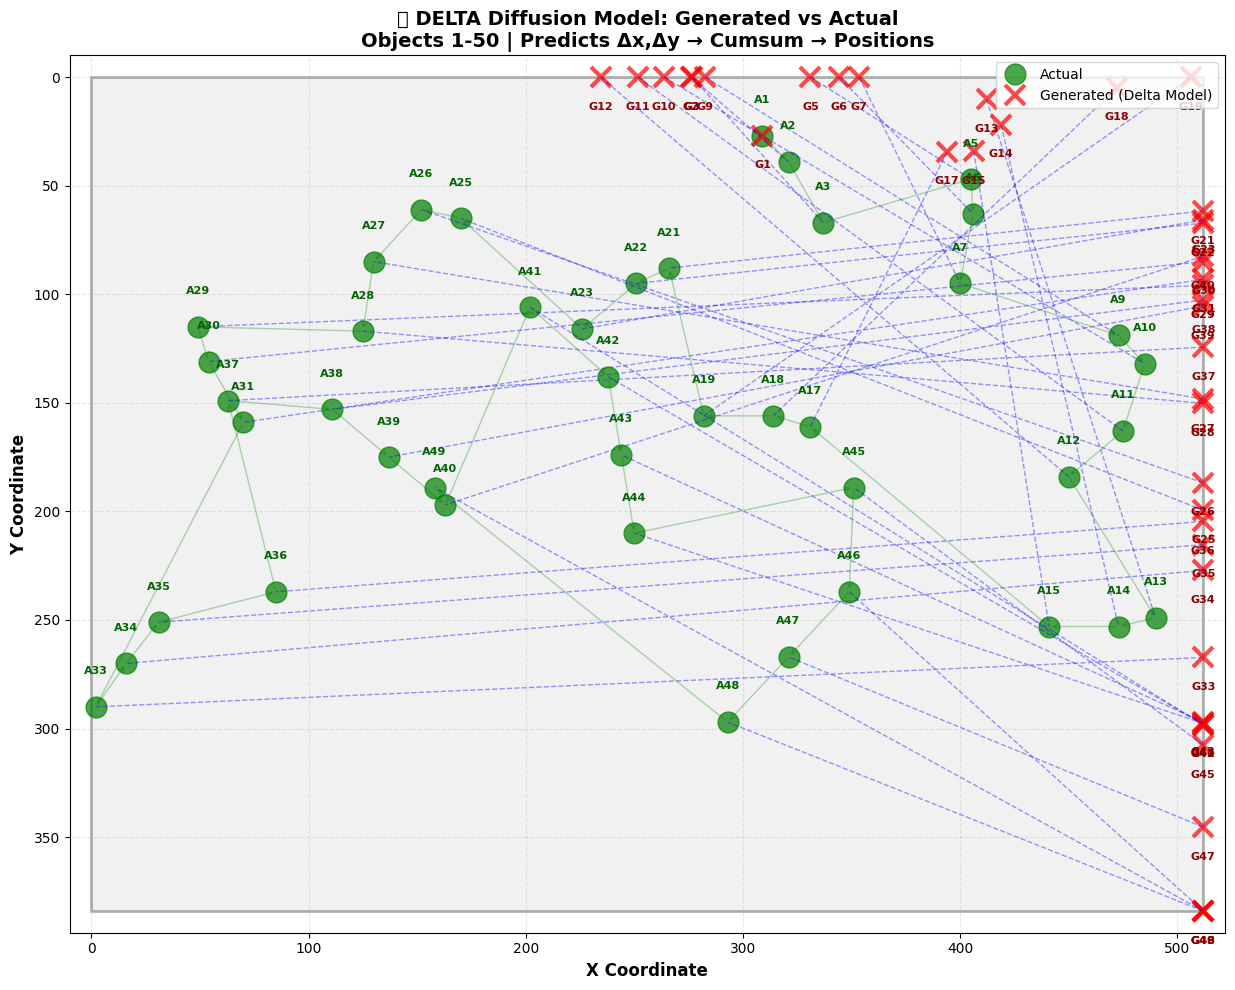


📊 DELTA MODEL STATISTICS
  Mean Error:   291.9 px
  Std Error:    127.4 px
  Min Error:    0.0 px
  Max Error:    510.5 px

  Generated Avg Movement: 39.3 px
  Actual Avg Movement:    50.9 px


In [17]:
# -------------------------------------------------
# Visualize DELTA Model: Generated vs Actual on 512x384 Play Area
# -------------------------------------------------

import matplotlib.pyplot as plt
import matplotlib.patches as patches

# ===== MODIFY THESE PARAMETERS =====
chunk_start = 0    # Starting index (0 for first object)
chunk_size = 50    # Number of hit objects to visualize
sample_idx = 3    # Which sample from test batch to use
# ====================================

# Load model if not already loaded
if 'diffusion_model' not in dir() or diffusion_model is None:
    print("Loading delta model...")
    diffusion_model = DualEncoderDiffusionModel(
        audio_dim=768, hyper_dim=7, delta_dim=2,
        hittype_embed_dim=32, time_embed_dim=64,
        d_model=256, nhead=8,
        num_audio_layers=6, num_decoder_layers=8,
        dropout=0.1, num_hittype_classes=6
    ).to(device)
    checkpoint = torch.load('/kaggle/input/delta-diffusion/best_diffusion_delta_model (1).pth', map_location=device)
    diffusion_model.load_state_dict(checkpoint['model'])
    print(f"✅ Loaded model (Val Loss: {checkpoint['val_loss']:.6f})")

diffusion_model.eval()

# Get a sample from test set
test_batch = next(iter(test_loader))
audio = test_batch['audio'][sample_idx:sample_idx+1].to(device)
hyper = test_batch['hyper'][sample_idx:sample_idx+1].to(device)
hittypes = test_batch['hittype'][sample_idx:sample_idx+1].to(device)
first_position = test_batch['first_position'][sample_idx:sample_idx+1].to(device)
actual_deltas = test_batch['beatmap_deltas'][sample_idx:sample_idx+1].to(device)
length = test_batch['lengths'][sample_idx].item()

print(f"🎯 Sample length: {length} hit objects")
print(f"🎯 First position: ({first_position[0,0].item():.3f}, {first_position[0,1].item():.3f})")

# Generate beatmap using DELTA model
print(f"\n🌊 Generating via Delta Diffusion Model (1000 steps)...")
generated_positions = sample_beatmap(
    diffusion_model, scheduler, 
    audio, hyper, hittypes, first_position,
    device
)

# Convert generated positions to screen coordinates
gen_pos = generated_positions[0, :length].cpu().numpy()
gen_x = (gen_pos[:, 0] + 1) / 2.0 * 512
gen_y = (gen_pos[:, 1] + 1) / 2.0 * 384

# Reconstruct actual positions from deltas
actual_deltas_np = actual_deltas[0, :length].cpu().numpy()
first_pos_np = first_position[0].cpu().numpy()

actual_x = np.zeros(length)
actual_y = np.zeros(length)
actual_x[0] = (first_pos_np[0] + 1) / 2.0 * 512
actual_y[0] = (first_pos_np[1] + 1) / 2.0 * 384

for i in range(1, length):
    actual_x[i] = actual_x[i-1] + (actual_deltas_np[i, 0] / 2.0 * 512)
    actual_y[i] = actual_y[i-1] + (actual_deltas_np[i, 1] / 2.0 * 384)

hittypes_np = hittypes[0, :length].cpu().numpy()

# Prepare chunk for visualization
chunk_end = min(chunk_start + chunk_size, length)
print(f"\n📊 Visualizing objects {chunk_start+1} to {chunk_end} (Total: {length})")

gen_x_chunk = gen_x[chunk_start:chunk_end]
gen_y_chunk = gen_y[chunk_start:chunk_end]
actual_x_chunk = actual_x[chunk_start:chunk_end]
actual_y_chunk = actual_y[chunk_start:chunk_end]
hittype_chunk = hittypes_np[chunk_start:chunk_end]

# Create figure
fig, ax = plt.subplots(figsize=(14, 10))

# Draw play area (512x384)
rect = patches.Rectangle((0, 0), 512, 384, linewidth=2, edgecolor='black', facecolor='lightgray', alpha=0.3)
ax.add_patch(rect)

hit_types = {0: 'Pad', 1: 'Normal', 2: 'Slider', 3: 'Spinner', 4: 'Combo', 5: 'Other'}

# Filter out padding
valid_indices = [i for i in range(len(hittype_chunk)) if hittype_chunk[i] > 0]

# Plot actual (green) and generated (red)
for idx, i in enumerate(valid_indices):
    ax.plot(actual_x_chunk[i], actual_y_chunk[i], 'go', markersize=15, alpha=0.7, 
            label='Actual' if idx == 0 else '')
    ax.plot(gen_x_chunk[i], gen_y_chunk[i], 'rx', markersize=15, markeredgewidth=3, alpha=0.7, 
            label='Generated (Delta Model)' if idx == 0 else '')
    
    # Labels
    ax.text(actual_x_chunk[i], actual_y_chunk[i] - 15, f'A{chunk_start+i+1}', 
            ha='center', fontsize=8, color='darkgreen', fontweight='bold')
    ax.text(gen_x_chunk[i], gen_y_chunk[i] + 15, f'G{chunk_start+i+1}', 
            ha='center', fontsize=8, color='darkred', fontweight='bold')
    
    # Error line
    ax.plot([gen_x_chunk[i], actual_x_chunk[i]], [gen_y_chunk[i], actual_y_chunk[i]], 
            'b--', alpha=0.4, linewidth=1)

# Draw sequence arrows
valid_list = list(valid_indices)
for idx in range(len(valid_list) - 1):
    i, j = valid_list[idx], valid_list[idx+1]
    ax.annotate('', xy=(actual_x_chunk[j], actual_y_chunk[j]), 
                xytext=(actual_x_chunk[i], actual_y_chunk[i]),
                arrowprops=dict(arrowstyle='->', color='green', alpha=0.3, lw=1))

ax.set_xlim(-10, 522)
ax.set_ylim(-10, 394)
ax.set_xlabel('X Coordinate', fontsize=12, fontweight='bold')
ax.set_ylabel('Y Coordinate', fontsize=12, fontweight='bold')
ax.set_title(f'🌊 DELTA Diffusion Model: Generated vs Actual\nObjects {chunk_start+1}-{chunk_end} | Predicts Δx,Δy → Cumsum → Positions', 
             fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, linestyle='--')
ax.legend(loc='upper right', fontsize=10)
ax.set_aspect('equal')
ax.invert_yaxis()

plt.tight_layout()
plt.show()

# Statistics
print("\n" + "=" * 70)
print("📊 DELTA MODEL STATISTICS")
print("=" * 70)

errors = []
for i in valid_indices:
    error_dist = np.sqrt((gen_x_chunk[i] - actual_x_chunk[i])**2 + 
                         (gen_y_chunk[i] - actual_y_chunk[i])**2)
    errors.append(error_dist)

print(f"  Mean Error:   {np.mean(errors):.1f} px")
print(f"  Std Error:    {np.std(errors):.1f} px")
print(f"  Min Error:    {np.min(errors):.1f} px")
print(f"  Max Error:    {np.max(errors):.1f} px")

# Movement comparison
gen_distances = np.sqrt(np.diff(gen_x_chunk[valid_indices])**2 + np.diff(gen_y_chunk[valid_indices])**2)
actual_distances = np.sqrt(np.diff(actual_x_chunk[valid_indices])**2 + np.diff(actual_y_chunk[valid_indices])**2)

print(f"\n  Generated Avg Movement: {gen_distances.mean():.1f} px")
print(f"  Actual Avg Movement:    {actual_distances.mean():.1f} px")
print("=" * 70)



In [20]:
# -------------------------------------------------
# FIXED: Training with Multi-Objective Loss (PROPERLY SCALED)
# Prevents delta collapse by adding auxiliary losses
# -------------------------------------------------

def compute_positions_from_deltas(deltas, first_position):
    """
    Convert deltas to absolute positions via cumulative sum.
    """
    batch_size, seq_len, _ = deltas.shape
    positions = torch.zeros_like(deltas)
    positions[:, 0] = first_position
    
    # Cumulative sum
    for i in range(1, seq_len):
        positions[:, i] = positions[:, i-1] + deltas[:, i]
    
    return positions


def compute_multi_objective_loss_v2(predicted_noise, actual_noise, 
                                     noisy_deltas, clean_deltas, 
                                     first_position, timesteps, scheduler,
                                     mask, device):
    """
    Multi-objective loss with PROPER SCALING to prevent delta collapse.
    
    All losses normalized to similar scale (~0.01 - 1.0)
    """
    
    # 1. Standard noise MSE loss (already ~1.0 scale)
    noise_loss = ((predicted_noise - actual_noise) ** 2 * mask).sum() / (mask.sum() * 2 + 1e-8)
    
    # 2. Predict clean deltas from noise (x0 prediction)
    timestep_cpu = timesteps.cpu()
    sqrt_alpha = scheduler.sqrt_alphas_cumprod[timestep_cpu].to(device).view(-1, 1, 1)
    sqrt_one_minus_alpha = scheduler.sqrt_one_minus_alphas_cumprod[timestep_cpu].to(device).view(-1, 1, 1)
    
    # Clamp to avoid explosion
    pred_clean_deltas = (noisy_deltas - sqrt_one_minus_alpha * predicted_noise) / (sqrt_alpha + 1e-8)
    pred_clean_deltas = torch.clamp(pred_clean_deltas, -2.0, 2.0)
    
    # 3. Delta MSE loss (direct supervision on predicted deltas)
    # This is the KEY fix - directly compare predicted vs target deltas
    delta_mse = ((pred_clean_deltas - clean_deltas) ** 2 * mask).sum() / (mask.sum() * 2 + 1e-8)
    
    # 4. Position boundary loss - penalize out-of-bounds cumsum
    pred_positions = compute_positions_from_deltas(pred_clean_deltas, first_position)
    boundary_violation = torch.relu(torch.abs(pred_positions) - 1.0) * mask
    boundary_loss = (boundary_violation ** 2).sum() / (mask.sum() * 2 + 1e-8)
    
    # 5. Movement magnitude matching (normalized)
    pred_magnitude = torch.sqrt((pred_clean_deltas ** 2).sum(dim=-1, keepdim=True) + 1e-8)
    target_magnitude = torch.sqrt((clean_deltas ** 2).sum(dim=-1, keepdim=True) + 1e-8)
    
    # Relative magnitude error (scale-invariant)
    magnitude_ratio = pred_magnitude / (target_magnitude + 1e-8)
    magnitude_loss = ((magnitude_ratio - 1.0) ** 2 * mask).sum() / (mask.sum() + 1e-8)
    
    # 6. Anti-collapse loss - penalize if movements are too small
    avg_pred_magnitude = (pred_magnitude * mask).sum() / (mask.sum() + 1e-8)
    avg_target_magnitude = (target_magnitude * mask).sum() / (mask.sum() + 1e-8)
    collapse_penalty = torch.relu(avg_target_magnitude * 0.5 - avg_pred_magnitude)  # Penalize if < 50% of target
    
    # Combine losses (all now ~0.01-1.0 scale)
    total_loss = (
        1.0 * noise_loss +           # Primary diffusion loss
        0.5 * delta_mse +            # Direct delta supervision
        0.1 * boundary_loss +        # Soft boundary constraint  
        0.1 * magnitude_loss +       # Relative magnitude matching
        0.5 * collapse_penalty       # Anti-collapse
    )
    
    return total_loss, {
        'noise': noise_loss.item(),
        'delta_mse': delta_mse.item(),
        'boundary': boundary_loss.item(),
        'magnitude': magnitude_loss.item(),
        'collapse': collapse_penalty.item(),
        'total': total_loss.item()
    }


def train_diffusion_epoch_v2(model, scheduler, loader, optimizer, device):
    """Train with properly scaled multi-objective loss."""
    model.train()
    total_losses = {'noise': 0, 'delta_mse': 0, 'boundary': 0, 'magnitude': 0, 'collapse': 0, 'total': 0}
    
    for batch_idx, batch in enumerate(loader):
        audio = batch['audio'].to(device)
        spatial_deltas = batch['beatmap_deltas'].to(device)
        hittypes = batch['hittype'].to(device)
        hyper = batch['hyper'].to(device)
        first_position = batch['first_position'].to(device)
        lengths = batch['lengths']
        
        batch_size = audio.size(0)
        
        prev_spatial_deltas = create_shifted_spatial_deltas(spatial_deltas)
        prev_hittypes = create_shifted_hittypes(hittypes)
        
        optimizer.zero_grad()
        
        # Sample timesteps
        timesteps = torch.randint(0, scheduler.num_timesteps, (batch_size,), device=device).long()
        
        # Add noise
        noise = torch.randn_like(spatial_deltas)
        noisy_deltas, noise = scheduler.add_noise(spatial_deltas, timesteps, noise)
        
        # Predict noise
        predicted_noise = model(
            noisy_deltas=noisy_deltas,
            timestep=timesteps,
            audio=audio,
            hyper=hyper,
            prev_spatial_deltas=prev_spatial_deltas,
            current_hittype=hittypes,
            prev_hittypes=prev_hittypes
        )
        
        # Create mask
        mask = torch.zeros(batch_size, audio.size(1), dtype=torch.bool, device=device)
        for i, length in enumerate(lengths):
            mask[i, :length] = True
        mask = mask.unsqueeze(-1).float()
        
        # Multi-objective loss (properly scaled)
        loss, loss_dict = compute_multi_objective_loss_v2(
            predicted_noise, noise,
            noisy_deltas, spatial_deltas,
            first_position, timesteps, scheduler,
            mask, device
        )
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        for k, v in loss_dict.items():
            total_losses[k] += v
        
        if (batch_idx + 1) % 50 == 0:
            print(f"  Batch {batch_idx+1}/{len(loader)} | "
                  f"Tot: {loss_dict['total']:.4f} | "
                  f"Noise: {loss_dict['noise']:.4f} | "
                  f"ΔMSE: {loss_dict['delta_mse']:.4f} | "
                  f"Mag: {loss_dict['magnitude']:.4f} | "
                  f"Coll: {loss_dict['collapse']:.4f}")
    
    return {k: v / len(loader) for k, v in total_losses.items()}


@torch.no_grad()
def validate_diffusion_v2(model, scheduler, loader, device):
    """Validate with properly scaled multi-objective loss."""
    model.eval()
    total_losses = {'noise': 0, 'delta_mse': 0, 'boundary': 0, 'magnitude': 0, 'collapse': 0, 'total': 0}
    
    for batch in loader:
        audio = batch['audio'].to(device)
        spatial_deltas = batch['beatmap_deltas'].to(device)
        hittypes = batch['hittype'].to(device)
        hyper = batch['hyper'].to(device)
        first_position = batch['first_position'].to(device)
        lengths = batch['lengths']
        
        batch_size = audio.size(0)
        
        prev_spatial_deltas = create_shifted_spatial_deltas(spatial_deltas)
        prev_hittypes = create_shifted_hittypes(hittypes)
        
        timesteps = torch.randint(0, scheduler.num_timesteps, (batch_size,), device=device).long()
        
        noise = torch.randn_like(spatial_deltas)
        noisy_deltas, noise = scheduler.add_noise(spatial_deltas, timesteps, noise)
        
        predicted_noise = model(
            noisy_deltas=noisy_deltas,
            timestep=timesteps,
            audio=audio,
            hyper=hyper,
            prev_spatial_deltas=prev_spatial_deltas,
            current_hittype=hittypes,
            prev_hittypes=prev_hittypes
        )
        
        mask = torch.zeros(batch_size, audio.size(1), dtype=torch.bool, device=device)
        for i, length in enumerate(lengths):
            mask[i, :length] = True
        mask = mask.unsqueeze(-1).float()
        
        _, loss_dict = compute_multi_objective_loss_v2(
            predicted_noise, noise,
            noisy_deltas, spatial_deltas,
            first_position, timesteps, scheduler,
            mask, device
        )
        
        for k, v in loss_dict.items():
            total_losses[k] += v
    
    return {k: v / len(loader) for k, v in total_losses.items()}


print("=" * 80)
print("✅ FIXED Loss Functions with PROPER SCALING!")
print("=" * 80)
print("""
🔧 LOSS COMPONENTS (all ~0.01-1.0 scale now):

1️⃣ Noise MSE (weight=1.0)
   • Standard diffusion loss
   
2️⃣ Delta MSE (weight=0.5) ⭐ NEW
   • Direct supervision on predicted deltas
   • Forces model to learn correct movements
   
3️⃣ Boundary Loss (weight=0.1)
   • Soft penalty for positions outside [-1, 1]
   
4️⃣ Magnitude Loss (weight=0.1)
   • RELATIVE magnitude matching (scale-invariant)
   • Penalizes if pred/target ratio ≠ 1
   
5️⃣ Anti-Collapse (weight=0.5) ⭐ NEW
   • Penalizes if avg movement < 50% of target
   • Directly prevents collapse to zero
""")

✅ FIXED Loss Functions with PROPER SCALING!

🔧 LOSS COMPONENTS (all ~0.01-1.0 scale now):

1️⃣ Noise MSE (weight=1.0)
   • Standard diffusion loss
   
2️⃣ Delta MSE (weight=0.5) ⭐ NEW
   • Direct supervision on predicted deltas
   • Forces model to learn correct movements
   
3️⃣ Boundary Loss (weight=0.1)
   • Soft penalty for positions outside [-1, 1]
   
4️⃣ Magnitude Loss (weight=0.1)
   • RELATIVE magnitude matching (scale-invariant)
   • Penalizes if pred/target ratio ≠ 1
   
5️⃣ Anti-Collapse (weight=0.5) ⭐ NEW
   • Penalizes if avg movement < 50% of target
   • Directly prevents collapse to zero



In [ ]:
# -------------------------------------------------
# RE-TRAIN with PROPERLY SCALED Multi-Objective Loss
# -------------------------------------------------

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print("=" * 80)
print("🔧 RE-TRAINING with PROPERLY SCALED Loss (Fixing Collapse)")
print("=" * 80)

# Re-initialize model (fresh start)
diffusion_model_v2 = DualEncoderDiffusionModel(
    audio_dim=768,
    hyper_dim=7,
    delta_dim=2,
    hittype_embed_dim=32,
    time_embed_dim=64,
    d_model=256,
    nhead=8,
    num_audio_layers=6,
    num_decoder_layers=8,
    dropout=0.1,
    num_hittype_classes=6
).to(device)

scheduler = DiffusionScheduler(
    num_timesteps=1000,
    beta_start=1e-4,
    beta_end=0.02
)

optimizer_v2 = torch.optim.AdamW(
    diffusion_model_v2.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

lr_scheduler_v2 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_v2, mode='min', patience=3, factor=0.5, verbose=True
)

print(f"\n✅ Model Parameters: {sum(p.numel() for p in diffusion_model_v2.parameters()):,}")
print(f"✅ Device: {device}")
print(f"\n📊 Expected loss scale: ~0.5-2.0 (NOT millions!)")

num_epochs = 30
best_val_loss = float('inf')
patience_counter = 0
early_stop_patience = 10

train_history_v2 = []
val_history_v2 = []

for epoch in range(num_epochs):
    print(f"\n{'='*80}")
    print(f"Epoch {epoch+1}/{num_epochs}")
    print(f"{'='*80}")
    
    # Train with new loss
    train_losses = train_diffusion_epoch_v2(
        diffusion_model_v2, scheduler,
        train_loader, optimizer_v2, device
    )
    
    # Validate
    val_losses = validate_diffusion_v2(
        diffusion_model_v2, scheduler,
        val_loader, device
    )
    
    train_history_v2.append(train_losses)
    val_history_v2.append(val_losses)
    
    lr_scheduler_v2.step(val_losses['total'])
    
    print(f"\n📊 Epoch {epoch+1} Summary:")
    print(f"   Train - Tot: {train_losses['total']:.4f} | Noise: {train_losses['noise']:.4f} | "
          f"ΔMSE: {train_losses['delta_mse']:.4f} | Collapse: {train_losses['collapse']:.4f}")
    print(f"   Val   - Tot: {val_losses['total']:.4f} | Noise: {val_losses['noise']:.4f} | "
          f"ΔMSE: {val_losses['delta_mse']:.4f} | Collapse: {val_losses['collapse']:.4f}")
    print(f"   LR: {optimizer_v2.param_groups[0]['lr']:.2e}")
    
    # Save best
    if val_losses['total'] < best_val_loss:
        best_val_loss = val_losses['total']
        patience_counter = 0
        torch.save({
            'epoch': epoch,
            'model': diffusion_model_v2.state_dict(),
            'optimizer': optimizer_v2.state_dict(),
            'train_losses': train_losses,
            'val_losses': val_losses
        }, 'best_diffusion_v2_model.pth')
        print(f"   ✅ Best model saved!")
    else:
        patience_counter += 1
        print(f"   No improvement ({patience_counter}/{early_stop_patience})")
    
    if patience_counter >= early_stop_patience:
        print(f"\n⚠️ Early stopping at epoch {epoch+1}")
        break

print("\n" + "=" * 80)
print("🎉 Training Complete!")
print(f"Best Val Loss: {best_val_loss:.6f}")
print("=" * 80)


🔧 RE-TRAINING with PROPERLY SCALED Loss (Fixing Collapse)

✅ Model Parameters: 13,661,890
✅ Device: cuda

📊 Expected loss scale: ~0.5-2.0 (NOT millions!)

Epoch 1/30
  Batch 50/601 | Tot: 7203373.0000 | Noise: 0.9990 | ΔMSE: 2.8100 | Mag: 72026336.0000 | Coll: 0.0000
